<style>
/* Компактная типографика markdown-ячеек */
.text_cell_render, .jp-RenderedMarkdown, .markdown-body {
    font-size: 13px !important;
    line-height: 1.45;
}
.jp-RenderedMarkdown h1, .markdown-body h1, .text_cell_render h1 { font-size: 1.55em !important; }
.jp-RenderedMarkdown h2, .markdown-body h2, .text_cell_render h2 { font-size: 1.22em !important; }
.jp-RenderedMarkdown h3, .markdown-body h3, .text_cell_render h3 { font-size: 1.06em !important; }
.jp-RenderedMarkdown h4, .markdown-body h4, .text_cell_render h4 { font-size: 1em !important; }
.jp-RenderedMarkdown p, .markdown-body p, .text_cell_render p { margin: 0.35em 0 !important; }
.jp-RenderedMarkdown li, .markdown-body li, .text_cell_render li { margin: 0.12em 0 !important; }
</style>

# Проверка гипотез для прогнозирования зарплаты

Ноутбук последовательно проверяет 21 гипотезу из плана. Данные — `job_postings_with_salaries.csv`: 9 173 вакансии, зарплаты приведены к **USD в год**, таргет — середина вилки `salary_mid = (min + max) / 2`.

Для каждой гипотезы: статистический тест или сравнение моделей на одной кросс-валидации, короткий вывод и график там, где он информативнее таблицы. В конце — сводная таблица и общие выводы.

**Как читать выводы.** p-value отвечает только на вопрос «есть ли различие», поэтому рядом указан размер эффекта (ε² для Kruskal–Wallis, прирост MAE для моделей). Проверки множественные, p-value здесь — ориентир, а не окончательное доказательство.

Для запуска нужны `pandas`, `numpy`, `scipy`, `scikit-learn`, `statsmodels`, `matplotlib`, `seaborn`.

In [1]:
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    mean_absolute_error,
    r2_score,
)
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, TargetEncoder

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.title_fontsize": 8,
        "figure.titlesize": 10,
    }
)
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8C8C8C"

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_data

## 0. Подготовка данных

Повторяем нормализацию из EDA: период → год (час × 2080, день × 260, неделя × 52, месяц × 12), валюта → USD по фиксированным курсам. Дополнительно сохраняем «сырой» период, потому что он сам по себе может быть признаком (гипотеза 16).

In [2]:
raw = load_data()
df = raw.dropna(subset=["salary_min", "salary_max"]).copy().reset_index(drop=True)

PERIOD_COEF = {"day": 260, "week": 52, "month": 12, "hour": 2080, "year": 1}
CURRENCY_COEF = {
    "USD": 1.0, "EUR": 0.89, "CAD": 1.42, "GBP": 0.75,
    "AUD": 1.45, "PLN": 3.9, "NZD": 1.78, "CHF": 0.83,
}

df["raw_period"] = df["salary_period"].astype(str)
df["raw_currency"] = df["salary_currency"].astype(str)
df["salary_min_usd"] = (
    df["salary_min"] * df["raw_period"].map(PERIOD_COEF) / df["raw_currency"].map(CURRENCY_COEF)
)
df["salary_max_usd"] = (
    df["salary_max"] * df["raw_period"].map(PERIOD_COEF) / df["raw_currency"].map(CURRENCY_COEF)
)
df["salary_mid"] = (df["salary_min_usd"] + df["salary_max_usd"]) / 2
df["log_salary"] = np.log1p(df["salary_mid"])
df["spread"] = df["salary_max_usd"] - df["salary_min_usd"]
df["spread_pct"] = df["spread"] / df["salary_mid"]

# Флаги выбросов по Тьюки — как в EDA, нужны для гипотезы 17.
def iqr_bounds(values):
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["salary_min_usd", "salary_max_usd"]:
    low, high = iqr_bounds(df[col])
    df[f"outlier_{col}"] = (df[col] < low) | (df[col] > high)
df["outlier_any"] = df["outlier_salary_min_usd"] | df["outlier_salary_max_usd"]
df["period_suspect"] = df["outlier_any"] & df["raw_period"].ne("year")

MISSING_FIELDS = [
    "seniority", "workplace_type", "country_code", "language",
    "department", "employment_type", "region", "city",
]
for col in MISSING_FIELDS:
    df[f"is_missing_{col}"] = df[col].isna().astype(int)

BASE = ["ats", "employment_type", "workplace_type", "country_code", "salary_source", "raw_period"]
for col in BASE:
    df[col] = df[col].fillna("Unknown").astype(str)

# Семейство профессии по title — грубая, но воспроизводимая эвристика.
FAMILY_PATTERNS = {
    "engineering": r"engineer|developer|software|devops|\bsre\b|data scientist|data engineer|machine learning|\bml\b|\bai\b|architect|programmer|\bqa\b|tester|security|cloud|backend|frontend|full[- ]stack|systems|database",
    "sales": r"\bsales\b|account executive|business development|\bbdr\b|\bsdr\b|account manager|partnership|revenue|territory",
    "healthcare": r"nurse|physician|medical|clinical|therapist|pharmac|dental|health|\brn\b|caregiver|surgeon|radiolog|patholog|behavior analyst",
    "finance": r"financ|accountant|accounting|controller|auditor|\btax\b|treasury|fp&a|investment|banker|underwrit|payroll|credit|actuar",
    "marketing": r"marketing|growth|\bseo\b|content|brand|social media|communications|public relations|copywriter|demand gen",
    "operations": r"operations|\bops\b|supply chain|logistics|warehouse|manufactur|production|procurement|inventory|maintenance|facilities|quality",
    "people": r"human resources|\bhr\b|recruit|talent|people|compensation|benefits",
    "customer": r"customer success|customer support|customer service|call center|client success|help desk|support specialist",
    "admin": r"assistant|coordinator|administrator|receptionist|office manager|executive assistant|scheduler|clerk",
    "legal": r"lawyer|legal|counsel|attorney|paralegal|compliance",
    "design_product": r"designer|product manager|product owner|\bux\b|\bui\b|user experience|product design",
    "education": r"teacher|instructor|professor|tutor|education|faculty|lecturer",
}

def job_family(title):
    text = str(title).lower()
    for family, pattern in FAMILY_PATTERNS.items():
        if re.search(pattern, text):
            return family
    return "other"

df["job_family"] = df["title"].map(job_family)

# Штат из location/region — только для США; для остальных "Unknown".
US_STATES = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA",
    "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE", "Florida": "FL", "Georgia": "GA",
    "Hawaii": "HI", "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
    "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA",
    "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS", "Missouri": "MO", "Montana": "MT",
    "Nebraska": "NE", "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM",
    "New York": "NY", "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
    "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC",
    "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT",
    "Virginia": "VA", "Washington": "WA", "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY",
    "District of Columbia": "DC",
}
STATE_ABBR = set(US_STATES.values())

def extract_state(row):
    text = f"{row.get('location', '')}, {row.get('region', '')}"
    for name, abbr in US_STATES.items():
        if re.search(r"\b" + re.escape(name) + r"\b", text, flags=re.I):
            return abbr
    for part in re.split(r"[,\|/]", text):
        token = part.strip().upper()
        if token in STATE_ABBR:
            return token
    for token in re.findall(r"\b([A-Z]{2})\b", text):
        if token in STATE_ABBR:
            return token
    return None

df["state"] = df.apply(extract_state, axis=1)
df["state_model"] = np.where(df["country_code"].eq("US"), df["state"].fillna("Unknown"), "Unknown")

df["posted"] = pd.to_datetime(df["posted_at"], utc=True)
df["first_seen"] = pd.to_datetime(df["first_seen_at"], utc=True)
df["lag_hours"] = (df["first_seen"] - df["posted"]).dt.total_seconds() / 3600
df["posted_dow"] = df["posted"].dt.day_name()
df["posted_hour"] = df["posted"].dt.hour
df["days_since_start"] = (df["posted"] - df["posted"].min()).dt.total_seconds() / 86400

FOLDS = list(KFold(5, shuffle=True, random_state=RANDOM_STATE).split(df))

print(f"Исходных строк: {len(raw):,}; в анализе: {len(df):,} (удалено {len(raw) - len(df)} без salary_min/max)")
print(f"Медиана середины вилки: ${df.salary_mid.median():,.0f}; skew исходной шкалы: {df.salary_mid.skew():.2f}; skew логарифма: {df.log_salary.skew():.2f}")
print(f"Кандидатов на ошибку периода (выброс + период ≠ year): {int(df.period_suspect.sum())}")
display(df[["title", "raw_period", "salary_min_usd", "salary_max_usd", "salary_mid", "ats", "country_code"]].head())

Исходных строк: 9,173; в анализе: 9,155 (удалено 18 без salary_min/max)
Медиана середины вилки: $99,500; skew исходной шкалы: 3.56; skew логарифма: -0.08
Кандидатов на ошибку периода (выброс + период ≠ year): 42


,title,raw_period,salary_min_usd,salary_max_usd,salary_mid,ats,country_code
0,"Instrument Engineer, On Call",year,"90,000.000","340,000.000","215,000.000",ashby,US
1,Content Coordinator,year,"55,172.414","62,068.966","58,620.690",greenhouse,AU
2,"Senior Cyber Security Engineer - Identity and Device Management, & Networking Security",year,"160,000.000","240,000.000","200,000.000",greenhouse,Unknown
3,"Vice President, Global Accounting",year,"213,030.000","286,670.000","249,850.000",lever,US
4,Platform Engineer - Workspace,year,"72,072.138","78,082.366","75,077.252",smartrecruiters,AU


### Вспомогательные функции

Одна и та же схема кросс-валидации (5 folds) используется для всех сравнений моделей, поэтому приросты MAE сопоставимы. Базовая модель — `HistGradientBoostingRegressor` на категориальных признаках `ats`, `employment_type`, `workplace_type`, `country_code`, `salary_source`, `raw_period`.

In [3]:
def pfmt(p):
    if p < 1e-300:
        return "<1e-300"
    if p < 1e-4:
        return f"{p:.1e}"
    return f"{p:.3f}"

def metrics(pred_log, actual):
    pred_log = np.asarray(pred_log)
    actual = np.asarray(actual)
    usd = np.expm1(pred_log)
    return {
        "MAE, $": int(round(mean_absolute_error(actual, usd))),
        "RMSLE": round(float(np.sqrt(np.mean((pred_log - np.log1p(actual)) ** 2))), 3),
        "R2 (log)": round(float(r2_score(np.log1p(actual), pred_log)), 3),
    }

def kruskal_table(data, value, group, min_n=20):
    d = data.dropna(subset=[value, group]).copy()
    counts = d.groupby(group).size()
    keep = counts[counts >= min_n].index
    d = d[d[group].isin(keep)]
    groups = [g[value].to_numpy() for _, g in d.groupby(group)]
    H, p = stats.kruskal(*groups)
    n, k = len(d), len(groups)
    eps2 = (H - k + 1) / (n - k) if n > k else np.nan
    table = d.groupby(group)[value].agg(["median", "size"]).sort_values("median", ascending=False)
    return {"H": H, "p": p, "eps2": eps2, "table": table, "n": n, "k": k}

def pairwise_mw(data, value, group, pairs):
    rows = []
    for a, b in pairs:
        x = data.loc[data[group].eq(a), value].dropna()
        y = data.loc[data[group].eq(b), value].dropna()
        if len(x) == 0 or len(y) == 0:
            continue
        _, p = stats.mannwhitneyu(x, y)
        rows.append({
            "группа A": a, "n A": len(x), "медиана A": round(x.median()),
            "группа B": b, "n B": len(y), "медиана B": round(y.median()),
            "p": p, "p (Bonferroni)": min(1.0, p * len(pairs)),
        })
    return pd.DataFrame(rows)

def make_hgb():
    return HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
        l2_regularization=1.0, random_state=RANDOM_STATE,
        early_stopping=False, categorical_features=None,
    )

def fit_hgb(X_train, y_train):
    cats = [c for c in X_train.columns if not pd.api.types.is_numeric_dtype(X_train[c])]
    nums = [c for c in X_train.columns if c not in cats]
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_part = encoder.fit_transform(X_train[cats].astype(str)) if cats else np.empty((len(X_train), 0))
    num_part = X_train[nums].to_numpy(dtype=float)
    mask = np.array([True] * len(cats) + [False] * len(nums))
    model = make_hgb()
    model.set_params(categorical_features=mask)
    model.fit(np.hstack([cat_part, num_part]), y_train)
    return model, encoder, cats, nums

def predict_hgb(fitted, X_test):
    model, encoder, cats, nums = fitted
    cat_part = encoder.transform(X_test[cats].astype(str)) if cats else np.empty((len(X_test), 0))
    num_part = X_test[nums].to_numpy(dtype=float)
    return model.predict(np.hstack([cat_part, num_part]))

def cv_predict(X, y, folds=FOLDS, extra=None):
    X = X.copy()
    if extra is not None:
        for key, values in extra.items():
            X[key] = np.asarray(values)
    pred = np.full(len(X), np.nan)
    for train_idx, test_idx in folds:
        fitted = fit_hgb(X.iloc[train_idx], y.iloc[train_idx])
        pred[test_idx] = predict_hgb(fitted, X.iloc[test_idx])
    return pred

def cv_predict_target_encoding(X, y, column, folds=FOLDS):
    X = X.reset_index(drop=True)
    y = y.reset_index(drop=True)
    groups = df[column].reset_index(drop=True)
    pred = np.full(len(X), np.nan)
    for train_idx, test_idx in folds:
        encoder = TargetEncoder(cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), smooth="auto")
        X_train = X.iloc[train_idx].copy()
        X_test = X.iloc[test_idx].copy()
        X_train["__target_enc"] = encoder.fit_transform(
            groups.iloc[train_idx].to_frame(), y.iloc[train_idx]
        ).ravel()
        X_test["__target_enc"] = encoder.transform(groups.iloc[test_idx].to_frame()).ravel()
        fitted = fit_hgb(X_train, y.iloc[train_idx])
        pred[test_idx] = predict_hgb(fitted, X_test)
    return pred

SUMMARY = []
def add_summary(number, hypothesis, method, result, verdict):
    SUMMARY.append({
        "№": number, "Гипотеза": hypothesis, "Проверка": method,
        "Ключевой результат": result, "Вывод": verdict,
    })

BASE_PRED = cv_predict(df[BASE], df.log_salary)
BASE_METRICS = metrics(BASE_PRED, df.salary_mid)
print("Базовая модель (5-fold CV):", BASE_METRICS)

Базовая модель (5-fold CV): {'MAE, $': 39934, 'RMSLE': 0.451, 'R2 (log)': 0.474}


## 1. Таргет и постановка задачи

### Гипотеза 1. Предсказывать логарифм зарплаты, а не саму зарплату

,"MAE, $",RMSLE,R2 (исходная шкала)
таргет,,,
salary_mid,41789,0.738,0.301
log1p(salary_mid),39934,0.451,0.279


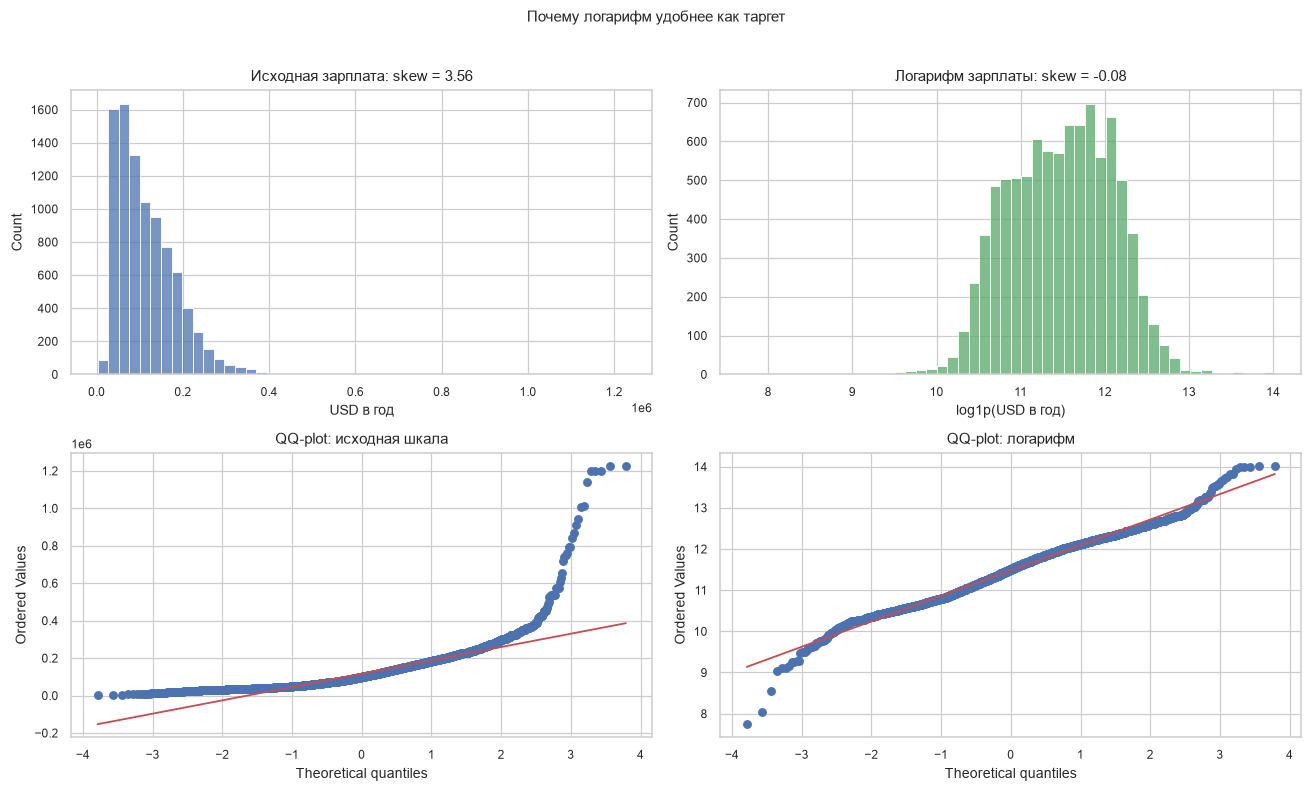

Jarque–Bera: исходная шкала p=<1e-300, логарифм p=0.005


In [4]:
skew_raw = df["salary_mid"].skew()
skew_log = df["log_salary"].skew()
jb_raw = stats.jarque_bera(df["salary_mid"])
jb_log = stats.jarque_bera(df["log_salary"])

pred_log = cv_predict(df[BASE], df.log_salary)
pred_raw = cv_predict(df[BASE], df.salary_mid)

h1 = pd.DataFrame(
    [
        {
            "таргет": "salary_mid",
            "MAE, $": int(round(mean_absolute_error(df.salary_mid, pred_raw))),
            "RMSLE": round(float(np.sqrt(np.mean((np.log1p(np.maximum(pred_raw, 1)) - df.log_salary) ** 2))), 3),
            "R2 (исходная шкала)": round(float(r2_score(df.salary_mid, pred_raw)), 3),
        },
        {
            "таргет": "log1p(salary_mid)",
            "MAE, $": int(round(mean_absolute_error(df.salary_mid, np.expm1(pred_log)))),
            "RMSLE": round(float(np.sqrt(np.mean((pred_log - df.log_salary) ** 2))), 3),
            "R2 (исходная шкала)": round(float(r2_score(df.salary_mid, np.expm1(pred_log))), 3),
        },
    ]
).set_index("таргет")
display(h1)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
sns.histplot(df.salary_mid, bins=50, ax=axes[0, 0], color=BLUE)
axes[0, 0].set_title(f"Исходная зарплата: skew = {skew_raw:.2f}")
axes[0, 0].set_xlabel("USD в год")
sns.histplot(df.log_salary, bins=50, ax=axes[0, 1], color=GREEN)
axes[0, 1].set_title(f"Логарифм зарплаты: skew = {skew_log:.2f}")
axes[0, 1].set_xlabel("log1p(USD в год)")
stats.probplot(df.salary_mid, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("QQ-plot: исходная шкала")
stats.probplot(df.log_salary, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("QQ-plot: логарифм")
fig.suptitle("Почему логарифм удобнее как таргет", y=1.02)
plt.tight_layout()
plt.show()

print(f"Jarque–Bera: исходная шкала p={pfmt(jb_raw.pvalue)}, логарифм p={pfmt(jb_log.pvalue)}")
add_summary(
    1, "Логарифм зарплаты как таргет", "skew, Jarque–Bera, CV с raw/log таргетом",
    f"skew {skew_raw:.2f} → {skew_log:.2f}; RMSLE {h1.loc['salary_mid','RMSLE']:.3f} → {h1.loc['log1p(salary_mid)','RMSLE']:.3f}; MAE ${h1.loc['salary_mid','MAE, $']:,} → ${h1.loc['log1p(salary_mid)','MAE, $']:,}",
    "Подтверждена (с оговоркой)",
)

**Вывод.** Логарифм убирает правую асимметрию (skew 3.56 → −0.08), заметно снижает относительную ошибку (RMSLE 0.738 → 0.451) и немного — MAE. R² на исходной шкале у log-модели чуть ниже (0.279 против 0.302): если бизнес-метрика — абсолютная ошибка в долларах, выбор неоднозначен, но для сравнения вакансий и интервалов log-таргет предпочтительнее.

### Гипотеза 2. Предсказывать середину диапазона, а не min и max по отдельности

,"MAE, $",RMSLE,R2 (log)
таргет,,,
min,34101,0.448,0.461
mid,39934,0.451,0.474
max,47163,0.468,0.466


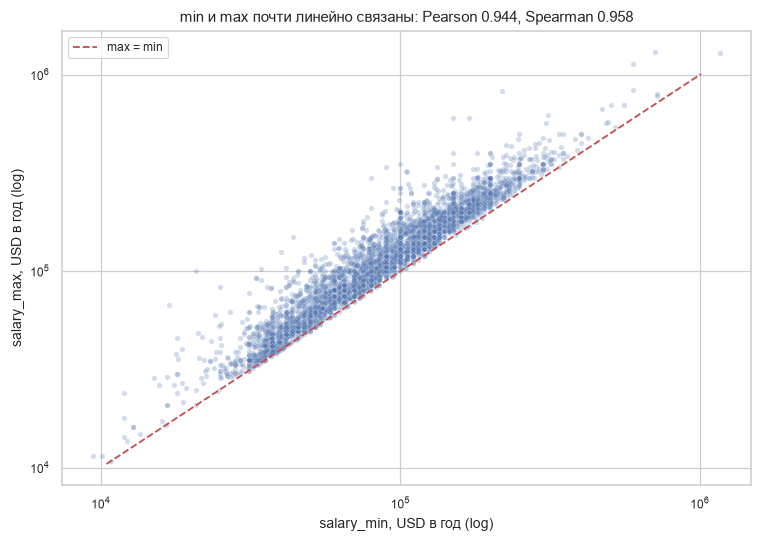

In [5]:
pearson_mm = df[["salary_min_usd", "salary_max_usd"]].corr().iloc[0, 1]
spearman_mm = stats.spearmanr(df["salary_min_usd"], df["salary_max_usd"]).statistic

target_rows = []
for name, col in [("min", "salary_min_usd"), ("mid", "salary_mid"), ("max", "salary_max_usd")]:
    pred = cv_predict(df[BASE], np.log1p(df[col]))
    m = metrics(pred, df[col])
    target_rows.append({"таргет": name, **m})
h2 = pd.DataFrame(target_rows).set_index("таргет")
display(h2)

plot_df = df.sample(min(4000, len(df)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=plot_df, x="salary_min_usd", y="salary_max_usd", alpha=0.25, s=12, ax=ax, color=BLUE)
lim = [df.salary_min_usd.quantile(0.001), df.salary_max_usd.quantile(0.999)]
ax.plot(lim, lim, color=RED, linestyle="--", label="max = min")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("salary_min, USD в год (log)"); ax.set_ylabel("salary_max, USD в год (log)")
ax.set_title(f"min и max почти линейно связаны: Pearson {pearson_mm:.3f}, Spearman {spearman_mm:.3f}")
ax.legend()
plt.tight_layout()
plt.show()

add_summary(
    2, "Один таргет — середина вилки", "Pearson/Spearman, CV для min/mid/max",
    f"r={pearson_mm:.3f}, ρ={spearman_mm:.3f}; RMSLE mid {h2.loc['mid','RMSLE']:.3f} против {h2.loc['min','RMSLE']:.3f}/{h2.loc['max','RMSLE']:.3f}",
    "Подтверждена",
)

**Вывод.** Границы вилки почти коллинеарны (Pearson 0.944, Spearman 0.958), поэтому отдельные модели для min и max дают почти ту же ошибку и дублируют информацию. Середина — компромиссный таргет: её R² максимален (0.474), а границы можно восстанавливать из неё и ширины вилки.

### Гипотеза 3. Ширина вилки — отдельный сигнал

,признак,R2 модели,R2 константы
0,spread_pct,0.083,0.000
1,log1p(spread),0.205,0.000


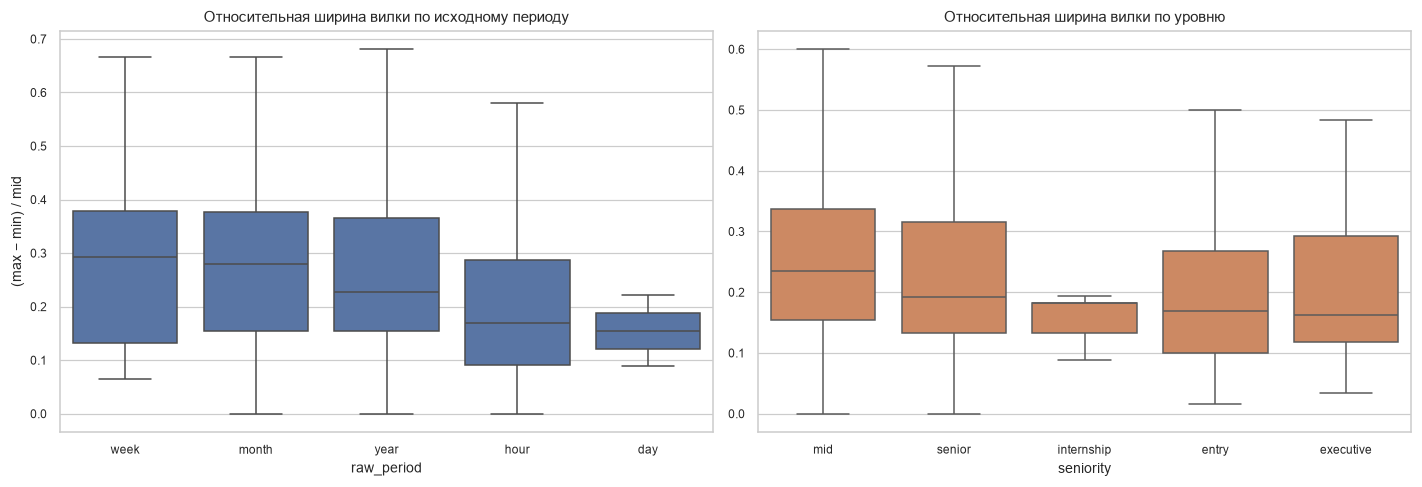

In [6]:
spread_corr = stats.spearmanr(df["spread"], df["salary_mid"])
spread_pct_corr = stats.spearmanr(df["spread_pct"], df["salary_mid"])
h3_sen = kruskal_table(df[df.seniority.notna()], "spread_pct", "seniority", min_n=10)
h3_emp = kruskal_table(df[df.employment_type.ne("Unknown")], "spread_pct", "employment_type", min_n=20)
h3_period = kruskal_table(df, "spread_pct", "raw_period", min_n=3)

pred_spread_pct = cv_predict(df[BASE], df.spread_pct)
pred_spread = cv_predict(df[BASE], np.log1p(df.spread))
r2_spread_pct = r2_score(df.spread_pct, pred_spread_pct)
r2_spread = r2_score(np.log1p(df.spread), pred_spread)

h3_table = pd.DataFrame(
    {
        "признак": ["spread_pct", "log1p(spread)"],
        "R2 модели": [r2_spread_pct, r2_spread],
        "R2 константы": [0.0, 0.0],
    }
)
display(h3_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order_period = df.groupby("raw_period")["spread_pct"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="raw_period", y="spread_pct", order=order_period, showfliers=False, ax=axes[0], color=BLUE)
axes[0].set_title("Относительная ширина вилки по исходному периоду")
axes[0].set_ylabel("(max − min) / mid")
sen_df = df[df.seniority.ne("Unknown")]
order_sen = sen_df.groupby("seniority")["spread_pct"].median().sort_values(ascending=False).index
sns.boxplot(data=sen_df, x="seniority", y="spread_pct", order=order_sen, showfliers=False, ax=axes[1], color=ORANGE)
axes[1].set_title("Относительная ширина вилки по уровню")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

add_summary(
    3, "Ширина вилки — отдельный сигнал", "Spearman, Kruskal–Wallis, CV на spread_pct",
    f"ρ(spread, mid)={spread_corr.statistic:.2f}, ρ(spread_pct, mid)={spread_pct_corr.statistic:.2f}; R2 spread_pct={r2_spread_pct:.3f}; Kruskal по period p={pfmt(h3_period['p'])}",
    "Частично подтверждена",
)

**Вывод.** Абсолютная ширина сильно растёт вместе с зарплатой (ρ = 0.75), то есть в основном повторяет уровень. Относительная ширина слабее связана с зарплатой (ρ = 0.24) и плохо предсказывается (R² = 0.08), хотя различия по периоду и типу занятости значимы. Как отдельный второй таргет ширина полезна скорее для интервалов, чем для основного прогноза.

## 2. Роль и уровень позиции

### Гипотеза 4. Уровень позиции положительно влияет на зарплату

,median,size
seniority,,
executive,"135,000.000",23
senior,"97,500.000",209
mid,"61,619.718",99
entry,"50,061.798",268
internship,"35,056.180",13


,группа A,n A,медиана A,группа B,n B,медиана B,p,p (Bonferroni)
0,entry,268,50062,mid,99,61620,0.004,0.012
1,mid,99,61620,senior,209,97500,0.000,0.000
2,senior,209,97500,executive,23,135000,0.124,0.371


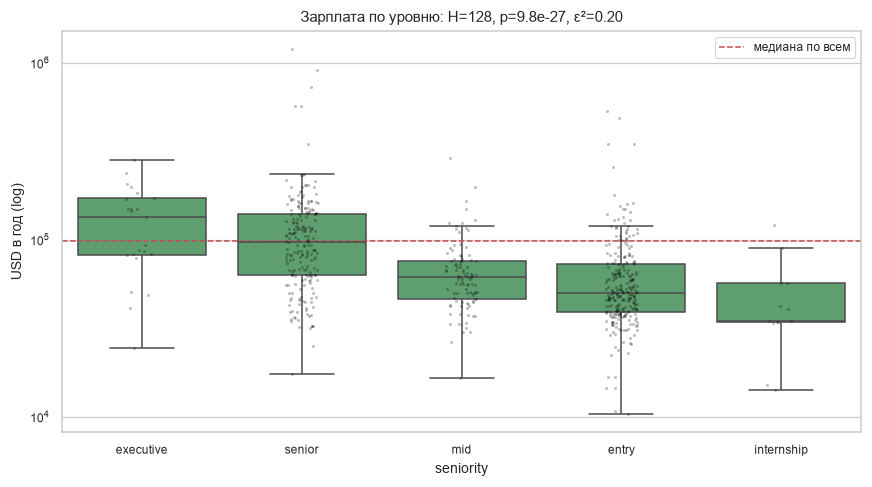

In [7]:
sen_df = df[df.seniority.notna()].copy()
h4 = kruskal_table(sen_df, "salary_mid", "seniority", min_n=10)
display(h4["table"])
h4_pairs = pairwise_mw(
    sen_df, "salary_mid", "seniority",
    [("entry", "mid"), ("mid", "senior"), ("senior", "executive")],
)
display(h4_pairs.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
order_sen = h4["table"].index
sns.boxplot(data=sen_df, x="seniority", y="salary_mid", order=order_sen, showfliers=False, ax=ax, color=GREEN)
sns.stripplot(data=sen_df, x="seniority", y="salary_mid", order=order_sen, color="black", alpha=0.25, size=2, ax=ax)
ax.axhline(df.salary_mid.median(), color=RED, linestyle="--", linewidth=1, label="медиана по всем")
ax.set_yscale("log"); ax.set_ylabel("USD в год (log)")
ax.set_title(f"Зарплата по уровню: H={h4['H']:.0f}, p={pfmt(h4['p'])}, ε²={h4['eps2']:.2f}")
ax.legend()
plt.tight_layout()
plt.show()

add_summary(
    4, "Уровень позиции влияет на зарплату", "Kruskal–Wallis + Mann–Whitney",
    f"ε²={h4['eps2']:.2f}; медианы entry→executive ${h4['table'].loc['entry','median']:,.0f}→${h4['table'].loc['executive','median']:,.0f}; senior vs executive p={pfmt(h4_pairs.iloc[2]['p'])}",
    "Подтверждена",
)

**Вывод.** Порядок уровней устойчив: entry 50.1k < mid 61.6k < senior 97.5k < executive 135k. Различия значимы, размер эффекта средний (ε² = 0.20). Пара senior–executive незначима (p = 0.12) из-за 23 наблюдений executive, но направление и медианы согласуются с гипотезой.

### Гипотеза 5. Уровень можно восстановить из `title`, несмотря на 93% пропусков

,median,size
seniority_pred,,
internship,"56,160.000",145
entry,"63,440.000",3693
mid,"92,017.000",721
senior,"133,100.000",4009
executive,"180,000.000",587


,"MAE, $",прирост к base
модель,,
base,"39,934.000",0.000
base + family,"37,739.000","2,195.000"
base + family + seniority (факт),"37,589.000","2,345.000"
base + family + seniority_pred,"34,606.000","5,328.000"


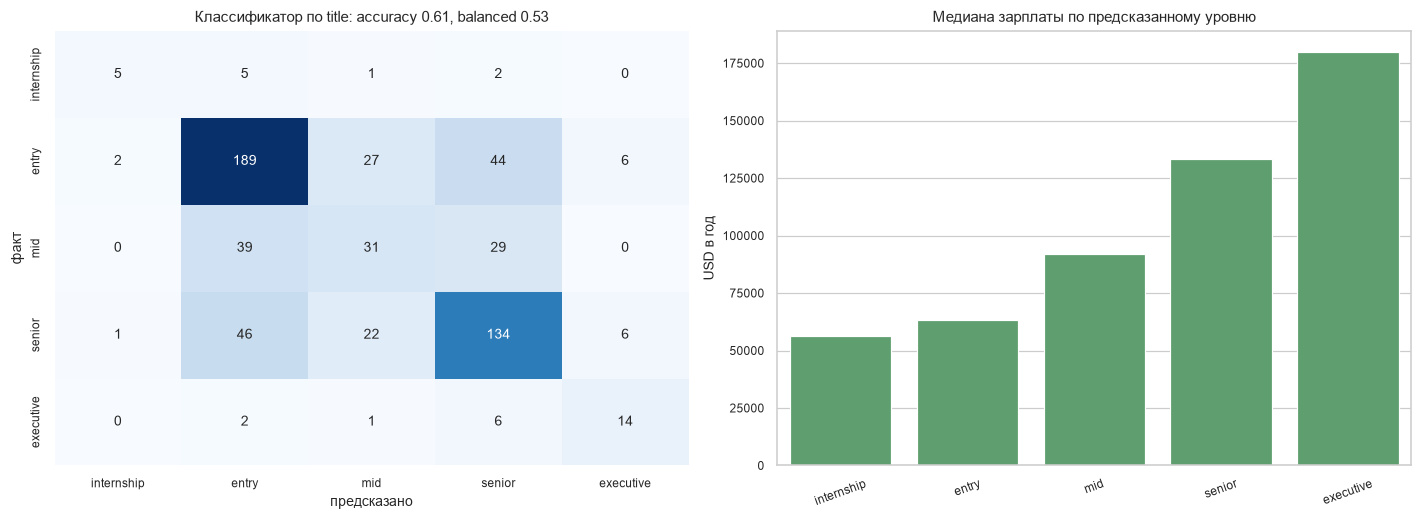

In [8]:
labeled = df[df.seniority.notna()].copy()
seniority_pipe = Pipeline(
    [
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
        ("logreg", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0)),
    ]
)
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
sen_pred_cv = cross_val_predict(
    seniority_pipe, labeled["title"].fillna(""), labeled["seniority"], cv=skf, n_jobs=-1
)
sen_acc = accuracy_score(labeled["seniority"], sen_pred_cv)
sen_bal = balanced_accuracy_score(labeled["seniority"], sen_pred_cv)
sen_majority = labeled["seniority"].value_counts(normalize=True).max()

seniority_pipe.fit(labeled["title"].fillna(""), labeled["seniority"])
df["seniority_pred"] = seniority_pipe.predict(df["title"].fillna(""))

sen_median = df.groupby("seniority_pred")["salary_mid"].agg(["median", "size"]).sort_values("median")
display(sen_median.round(0))

# Сравнение вклада: сама колонка seniority (93% пропусков) против предсказания из title.
comp_base = mean_absolute_error(df.salary_mid, np.expm1(BASE_PRED))
family_pred = cv_predict(df[BASE], df.log_salary, extra={"job_family": df["job_family"]})
comp_family = mean_absolute_error(df.salary_mid, np.expm1(family_pred))
senpred_pred = cv_predict(df[BASE], df.log_salary, extra={"job_family": df["job_family"], "seniority_pred": df["seniority_pred"]})
comp_senpred = mean_absolute_error(df.salary_mid, np.expm1(senpred_pred))
senact_pred = cv_predict(df[BASE], df.log_salary, extra={"job_family": df["job_family"], "seniority": df["seniority"]})
comp_senact = mean_absolute_error(df.salary_mid, np.expm1(senact_pred))

h5_table = pd.DataFrame(
    {
        "модель": ["base", "base + family", "base + family + seniority (факт)", "base + family + seniority_pred"],
        "MAE, $": [comp_base, comp_family, comp_senact, comp_senpred],
    }
)
h5_table["прирост к base"] = h5_table["MAE, $"].iloc[0] - h5_table["MAE, $"]
display(h5_table.round(0).set_index("модель"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
labels = ["internship", "entry", "mid", "senior", "executive"]
cm = confusion_matrix(labeled["seniority"], sen_pred_cv, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=axes[0], cbar=False)
axes[0].set_xlabel("предсказано"); axes[0].set_ylabel("факт")
axes[0].set_title(f"Классификатор по title: accuracy {sen_acc:.2f}, balanced {sen_bal:.2f}")
sns.barplot(data=sen_median.reset_index(), x="seniority_pred", y="median", ax=axes[1], color=GREEN)
axes[1].set_title("Медиана зарплаты по предсказанному уровню")
axes[1].set_ylabel("USD в год"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

add_summary(
    5, "Уровень восстанавливается из title", "TF-IDF + LogisticRegression, 5-fold; прирост MAE",
    f"accuracy {sen_acc:.2f} против majority {sen_majority:.2f}; base+family ${comp_family:,.0f} → +seniority_pred ${comp_senpred:,.0f}",
    "Частично подтверждена",
)

**Вывод.** Уровень действительно частично читается по названию: accuracy 0.61 против 0.44 у мажоритарного класса, balanced accuracy 0.53. Предсказанный уровень упорядочивает зарплаты (entry 63k → executive 180k) и даёт заметный прирост модели поверх семейства профессий (MAE 37.7k → 34.6k). Но точная классификация шумная, особенно для mid и internship; как единственный признак «уровень» теряет информацию, поэтому title лучше использовать и напрямую (TF-IDF/эмбеддинги).

### Гипотеза 6. Семейство профессии значимо

,median,size
job_family,,
legal,"161,500.000",137
design_product,"156,425.000",182
engineering,"149,725.000",1822
marketing,"120,000.000",377
people,"113,650.000",206
finance,"113,182.218",370
sales,"105,000.000",936
healthcare,"93,492.800",594
other,"78,000.000",3133


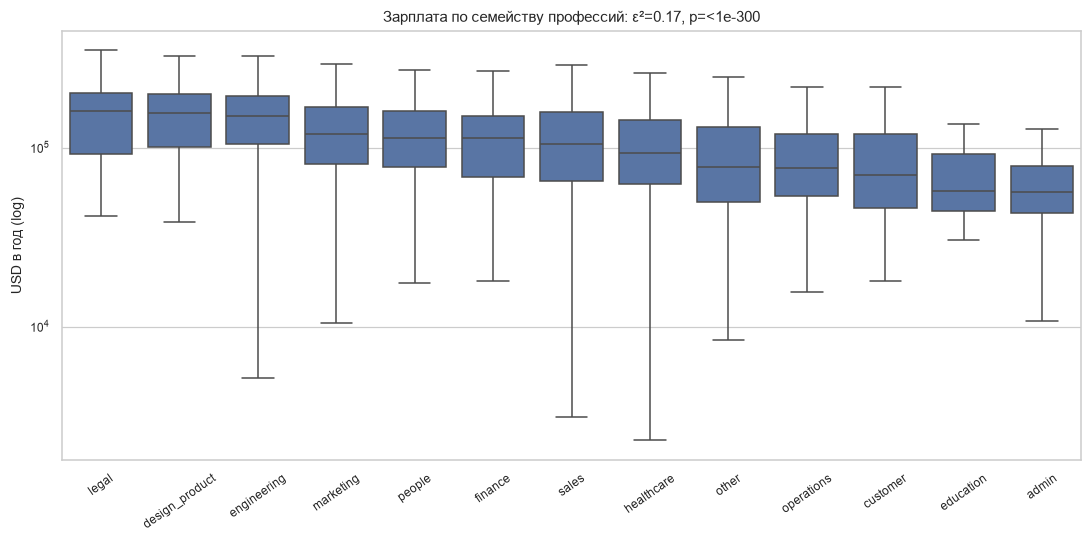

In [9]:
h6 = kruskal_table(df, "salary_mid", "job_family", min_n=50)
display(h6["table"])
family_pred = cv_predict(df[BASE], df.log_salary, extra={"job_family": df["job_family"]})
h6_gain = mean_absolute_error(df.salary_mid, np.expm1(BASE_PRED)) - mean_absolute_error(df.salary_mid, np.expm1(family_pred))

fig, ax = plt.subplots(figsize=(10, 5))
order_family = h6["table"].index
sns.boxplot(data=df, x="job_family", y="salary_mid", order=order_family, showfliers=False, ax=ax, color=BLUE)
ax.set_yscale("log"); ax.set_ylabel("USD в год (log)"); ax.set_xlabel("")
ax.set_title(f"Зарплата по семейству профессий: ε²={h6['eps2']:.2f}, p={pfmt(h6['p'])}")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

add_summary(
    6, "Семейство профессии значимо", "Kruskal–Wallis + CV с job_family",
    f"ε²={h6['eps2']:.2f}; медианы ${h6['table']['median'].min():,.0f}–${h6['table']['median'].max():,.0f}; прирост MAE ${h6_gain:,.0f}",
    "Подтверждена",
)

**Вывод.** Семейства различаются сильно (ε² = 0.17): legal/design/engineering — около 150k и выше, admin/education/customer — ниже 70k. Признак `job_family` даёт модели прирост MAE около 2.2k, то есть агрегация title работает. Эвристика относит 34% вакансий в `other`, поэтому для продакшена её стоит заменить на обучаемый классификатор или title-эмбеддинги.

### Гипотеза 7. `department` полезен там, где заполнен (59%)

,median,size
dept_group,,
Engineering,"185,125.000",374
Product,"183,467.500",93
Legal,"173,250.000",44
GTM,"162,500.000",33
Growth,"155,000.000",33
People,"150,000.000",46
Sales,"140,000.000",248
Finance,"137,500.000",91
Marketing,"135,000.000",157


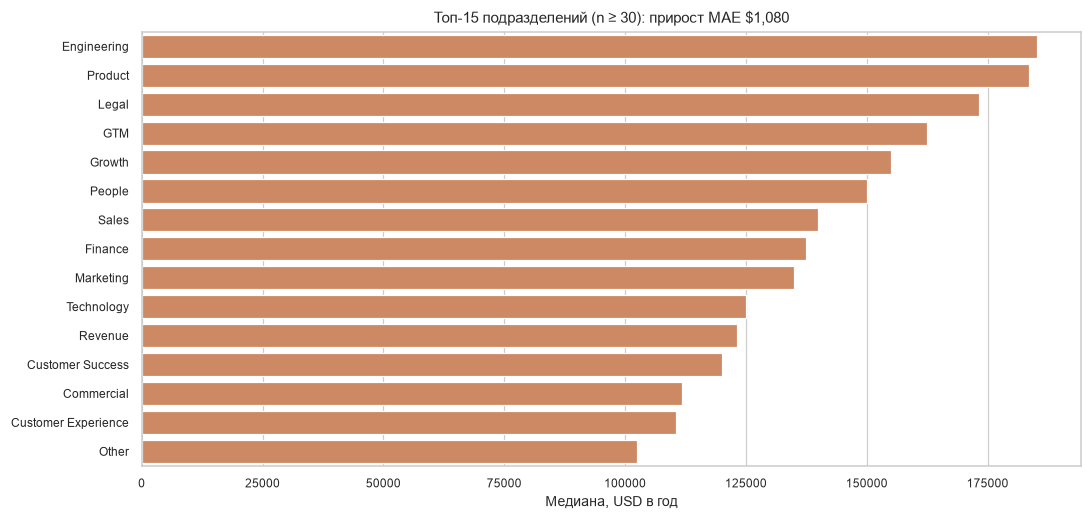

In [10]:
dept_df = df[df.department.notna()].copy()
dept_freq = dept_df["department"].value_counts()
dept_df["dept_group"] = dept_df["department"].where(dept_df["department"].map(dept_freq) >= 30, "Other")
h7 = kruskal_table(dept_df, "salary_mid", "dept_group", min_n=20)
display(h7["table"])

dept_folds = list(KFold(5, shuffle=True, random_state=RANDOM_STATE).split(dept_df))
dept_base = cv_predict(dept_df[BASE], dept_df.log_salary, folds=dept_folds)
dept_with = cv_predict(
    dept_df[BASE], dept_df.log_salary, folds=dept_folds, extra={"dept_group": dept_df["dept_group"]}
)
dept_gain = mean_absolute_error(dept_df.salary_mid, np.expm1(dept_base)) - mean_absolute_error(
    dept_df.salary_mid, np.expm1(dept_with)
)

fig, ax = plt.subplots(figsize=(10, 4.8))
top_dept = h7["table"].head(15).reset_index()
sns.barplot(data=top_dept, y="dept_group", x="median", ax=ax, color=ORANGE)
ax.set_xlabel("Медиана, USD в год"); ax.set_ylabel("")
ax.set_title(f"Топ-15 подразделений (n ≥ 30): прирост MAE ${dept_gain:,.0f}")
plt.tight_layout()
plt.show()

add_summary(
    7, "department полезен там, где заполнен", "Kruskal–Wallis и CV на подвыборке с department",
    f"n={len(dept_df):,}; ε²={h7['eps2']:.2f}; Engineering ${h7['table'].loc['Engineering','median']:,.0f} против Retail ${h7['table'].loc['Retail','median']:,.0f}; прирост MAE ${dept_gain:,.0f}",
    "Подтверждена (на подвыборке)",
)

**Вывод.** Внутри заполненной части `department` силён: Engineering 185k, Product 183k, Retail 39k; прирост MAE около 1.1k. Но поле заполнено только у 59% и имеет 2 202 значений, поэтому использовать его нужно с группировкой редких категорий и отдельной категорией «нет данных». Сам пропуск при этом информативен (медиана 82k против 115k), см. гипотезу 19.

## 3. География и формат работы

### Гипотеза 8. `country_code` значимо влияет на зарплату

,median,size
country_code,,
US,"107,500.000",6619
DE,"78,932.584",70
AU,"76,363.276",54
GB,"68,406.333",240
CA,"61,619.718",538
NL,"60,674.157",101
IT,"44,494.382",77
FR,"40,338.202",98


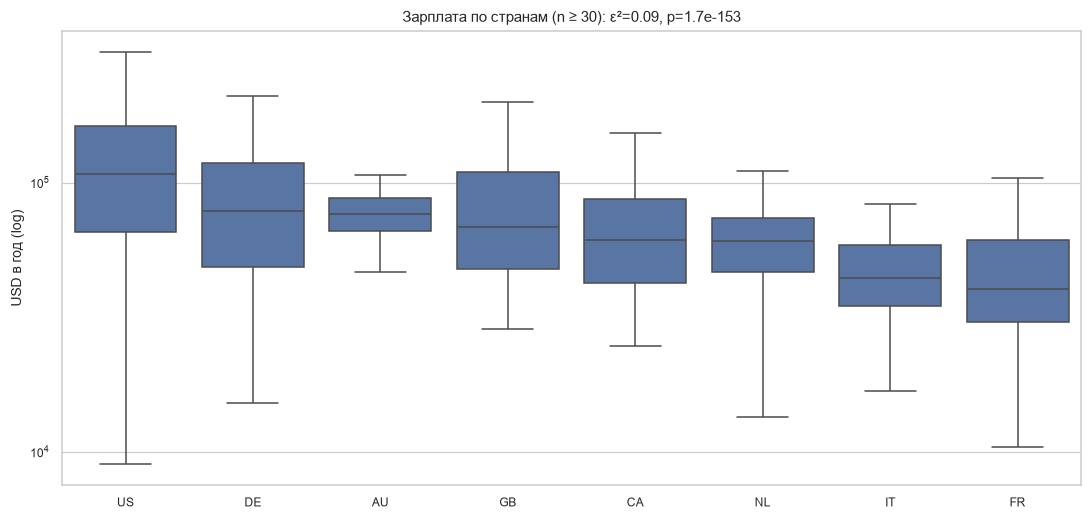

In [11]:
country_df = df[df.country_code.ne("Unknown")].copy()
h8 = kruskal_table(country_df, "salary_mid", "country_code", min_n=30)
display(h8["table"])

fig, ax = plt.subplots(figsize=(10, 4.8))
order_country = h8["table"].index
sns.boxplot(data=country_df[country_df.country_code.isin(order_country)], x="country_code", y="salary_mid", order=order_country, showfliers=False, ax=ax, color=BLUE)
ax.set_yscale("log"); ax.set_ylabel("USD в год (log)"); ax.set_xlabel("")
ax.set_title(f"Зарплата по странам (n ≥ 30): ε²={h8['eps2']:.2f}, p={pfmt(h8['p'])}")
plt.tight_layout()
plt.show()

add_summary(
    8, "Страна значимо влияет на зарплату", "Kruskal–Wallis по country_code",
    f"ε²={h8['eps2']:.2f}; US ${h8['table'].loc['US','median']:,.0f}, FR ${h8['table'].loc['FR','median']:,.0f}, IT ${h8['table'].loc['IT','median']:,.0f}",
    "Подтверждена",
)

**Вывод.** Страна — один из сильных признаков (ε² = 0.09): США 107.5k, Германия 78.9k, Франция 40.3k, Италия 44.5k. Разрыв объясняется и рынком, и составом вакансий (в США больше tech/senior), поэтому для модели это скорее совместный сигнал «страна + роль», а не чистая поправка на стоимость жизни.

### Гипотеза 9. remote > hybrid > onsite

,median,size
workplace_type,,
remote,"130,000.000",1730
hybrid,"117,575.000",1024
onsite,"76,960.000",1254


,группа A,n A,медиана A,группа B,n B,медиана B,p,p (Bonferroni)
0,remote,1730,130000,hybrid,1024,117575,0.011,0.033
1,remote,1730,130000,onsite,1254,76960,0.000,0.000
2,hybrid,1024,117575,onsite,1254,76960,0.000,0.000


,"без контроля, %","с контролем, %",p (с контролем)
remote,45.379,5.940,0.015
hybrid,37.717,3.028,0.186


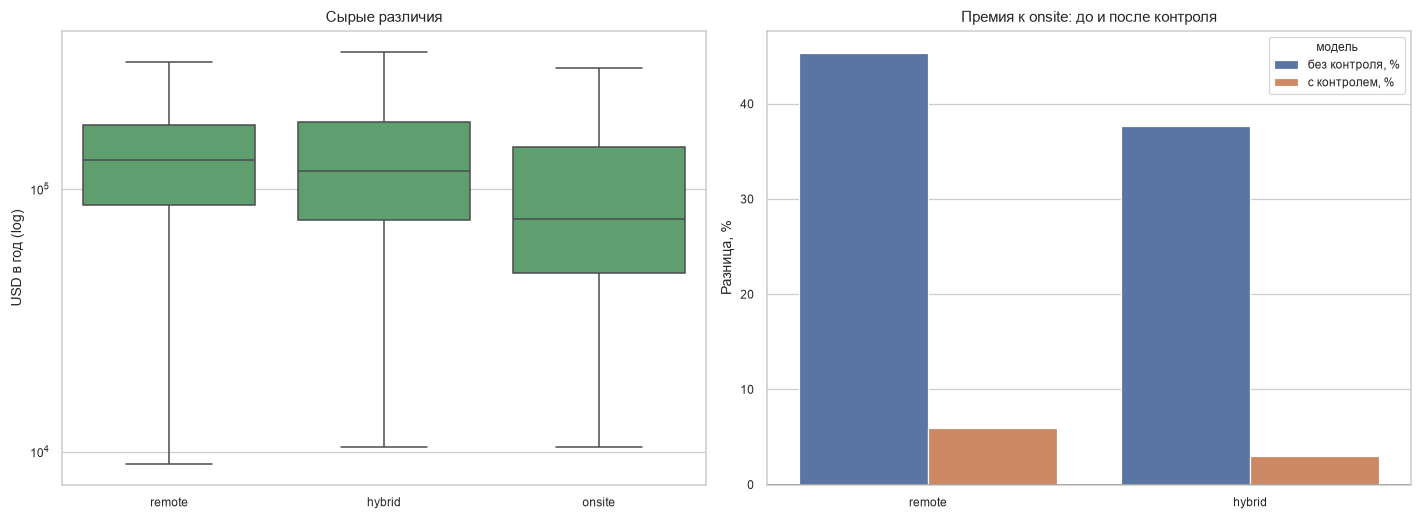

In [12]:
work_df = df[df.workplace_type.ne("Unknown")].copy()
h9 = kruskal_table(work_df, "salary_mid", "workplace_type", min_n=20)
display(h9["table"])
h9_pairs = pairwise_mw(work_df, "salary_mid", "workplace_type", [("remote", "hybrid"), ("remote", "onsite"), ("hybrid", "onsite")])
display(h9_pairs.round(3))

ols_raw = smf.ols('log_salary ~ C(workplace_type, Treatment("onsite"))', data=work_df).fit(cov_type="HC1")
ols_adj = smf.ols(
    'log_salary ~ C(workplace_type, Treatment("onsite")) + C(ats) + C(job_family) + C(employment_type) + C(raw_period)',
    data=work_df,
).fit(cov_type="HC1")

coef_names = {
    "remote": 'C(workplace_type, Treatment("onsite"))[T.remote]',
    "hybrid": 'C(workplace_type, Treatment("onsite"))[T.hybrid]',
}
coef_table = pd.DataFrame(
    {
        "без контроля, %": {k: (np.exp(ols_raw.params[v]) - 1) * 100 for k, v in coef_names.items()},
        "с контролем, %": {k: (np.exp(ols_adj.params[v]) - 1) * 100 for k, v in coef_names.items()},
        "p (с контролем)": {k: ols_adj.pvalues[v] for k, v in coef_names.items()},
    }
)
display(coef_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
order_w = h9["table"].index
sns.boxplot(data=work_df, x="workplace_type", y="salary_mid", order=order_w, showfliers=False, ax=axes[0], color=GREEN)
axes[0].set_yscale("log"); axes[0].set_title("Сырые различия"); axes[0].set_ylabel("USD в год (log)"); axes[0].set_xlabel("")
plot_coef = coef_table[["без контроля, %", "с контролем, %"]].reset_index().melt(id_vars="index", var_name="модель", value_name="%")
sns.barplot(data=plot_coef, x="index", y="%", hue="модель", ax=axes[1])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Премия к onsite: до и после контроля"); axes[1].set_xlabel(""); axes[1].set_ylabel("Разница, %")
plt.tight_layout()
plt.show()

add_summary(
    9, "remote > hybrid > onsite", "Kruskal–Wallis, Mann–Whitney, OLS с контролем на ats/роль/занятость/период",
    f"медианы ${h9['table'].loc['remote','median']:,.0f}/${h9['table'].loc['hybrid','median']:,.0f}/${h9['table'].loc['onsite','median']:,.0f}; remote +{coef_table.loc['remote','без контроля, %']:.0f}% → +{coef_table.loc['remote','с контролем, %']:.1f}% (p={pfmt(coef_table.loc['remote','p (с контролем)'])})",
    "Частично подтверждена",
)

**Вывод.** Сырые медианы дают ожидаемый порядок remote 130k > hybrid 117.6k > onsite 77k, но это в основном состав выборки. После контроля на ATS, семейство, занятость и период премия remote падает с +45% до +5.9% (p = 0.015), а hybrid становится незначимой (+3.0%, p = 0.19). Формат работы — слабый самостоятельный признак, но remote всё же немного выше onsite при прочих равных.

### Гипотеза 10. Внутри США город и штат значимы

,median,size
state,,
CA,"145,000.000",1332
NY,"129,000.000",780
WA,"113,682.500",267
MA,"107,500.000",289
VA,"105,000.000",205
CT,"103,750.000",52
NJ,"98,280.000",138
CO,"95,500.000",223
FL,"95,000.000",141


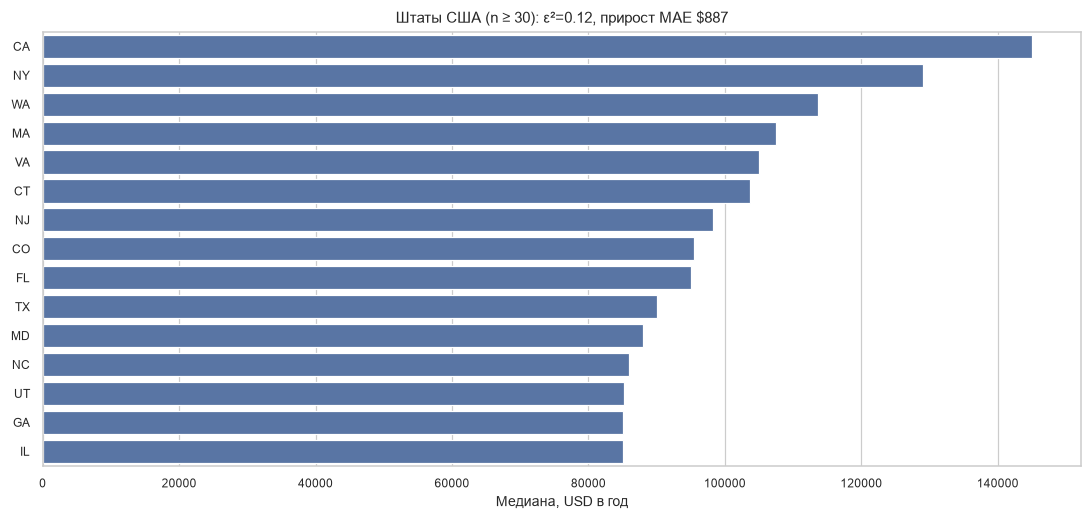

In [13]:
us_df = df[df.country_code.eq("US")].copy()
state_coverage = us_df["state"].notna().mean()
us_known_state = us_df[us_df["state"].notna()].copy()
h10 = kruskal_table(us_known_state, "salary_mid", "state", min_n=30)
display(h10["table"].head(20))

us_folds = list(KFold(5, shuffle=True, random_state=RANDOM_STATE).split(us_df))
us_base_cols = ["ats", "employment_type", "workplace_type", "salary_source", "raw_period"]
us_base = cv_predict(us_df[us_base_cols], us_df.log_salary, folds=us_folds)
us_state = cv_predict(us_df[us_base_cols], us_df.log_salary, folds=us_folds, extra={"state_model": us_df["state_model"]})
state_gain = mean_absolute_error(us_df.salary_mid, np.expm1(us_base)) - mean_absolute_error(us_df.salary_mid, np.expm1(us_state))

fig, ax = plt.subplots(figsize=(10, 4.8))
top_states = h10["table"].head(15).reset_index()
sns.barplot(data=top_states, y="state", x="median", ax=ax, color=BLUE)
ax.set_xlabel("Медиана, USD в год"); ax.set_ylabel("")
ax.set_title(f"Штаты США (n ≥ 30): ε²={h10['eps2']:.2f}, прирост MAE ${state_gain:,.0f}")
plt.tight_layout()
plt.show()

add_summary(
    10, "Внутри США штат/город значимы", "Kruskal–Wallis по извлечённым штатам + CV на подвыборке США",
    f"покрытие штата {state_coverage:.0%}; ε²={h10['eps2']:.2f}; CA ${h10['table'].loc['CA','median']:,.0f}, NY ${h10['table'].loc['NY','median']:,.0f}, TN ${h10['table'].loc['TN','median']:,.0f}; прирост MAE ${state_gain:,.0f}",
    "Подтверждена",
)

**Вывод.** Штат извлекается из `location`/`region` для 82% американских вакансий. Различия сильные (ε² = 0.12): Калифорния 145k, Нью-Йорк 129k, Теннесси 58k. Добавление штата к модели на подвыборке США снижает MAE на ~0.9k, то есть география внутри страны действительно полезна. Отдельно `city` не проверялся: 800 значений и ещё больше шума, чем у штата.

### Гипотеза 11. Пропуск `country_code` — сигнал, а не случайность

,группа,n,"медиана, $"
0,нет country_code,1122,"129,300.000"
1,есть country_code,8033,"95,500.000"
2,только US,6619,"107,500.000"


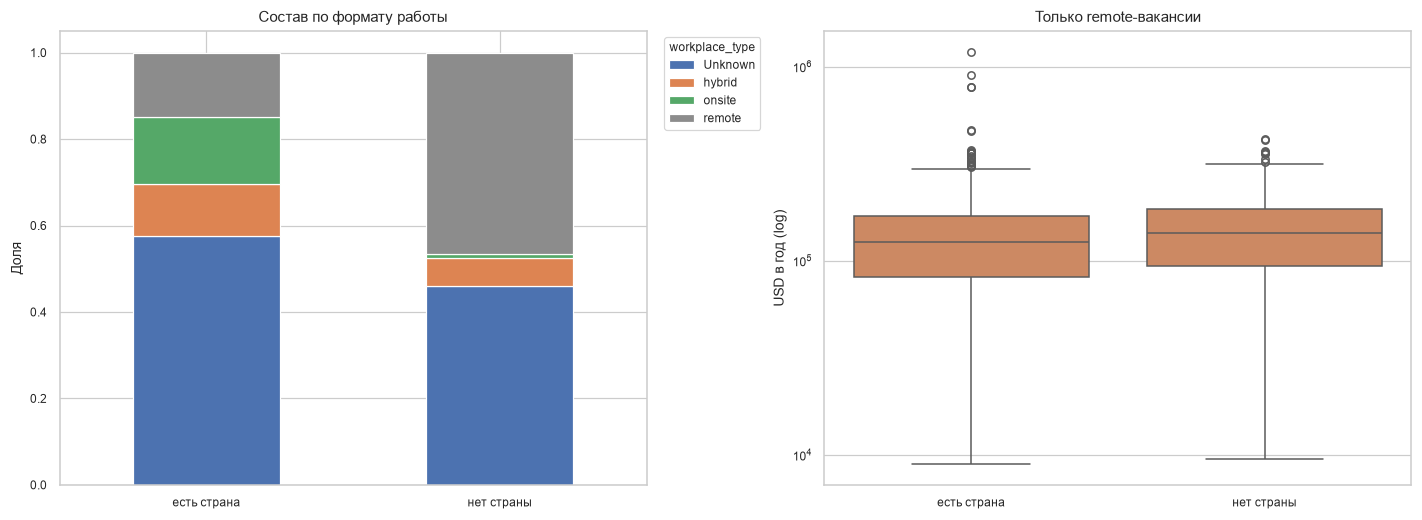

In [14]:
no_country = df[df.is_missing_country_code.eq(1)]
with_country = df[df.is_missing_country_code.eq(0)]
us_only = df[df.country_code.eq("US")]
h11_med = pd.DataFrame(
    {
        "группа": ["нет country_code", "есть country_code", "только US"],
        "n": [len(no_country), len(with_country), len(us_only)],
        "медиана, $": [no_country.salary_mid.median(), with_country.salary_mid.median(), us_only.salary_mid.median()],
    }
)
display(h11_med.round(0))

ct_workplace = pd.crosstab(df["is_missing_country_code"], df["workplace_type"], normalize="index")
chi2_w, p_w, _, _ = stats.chi2_contingency(pd.crosstab(df["is_missing_country_code"], df["workplace_type"]))
remote_share_missing = (no_country.workplace_type == "remote").mean()
remote_share_present = (with_country.workplace_type == "remote").mean()
greenhouse_share_missing = (no_country.ats == "greenhouse").mean()
greenhouse_share_present = (with_country.ats == "greenhouse").mean()

remote_missing = no_country.loc[no_country.workplace_type.eq("remote"), "salary_mid"]
remote_present = with_country.loc[with_country.workplace_type.eq("remote"), "salary_mid"]
p_remote = stats.mannwhitneyu(remote_missing, remote_present).pvalue

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ct_workplace.plot(kind="bar", stacked=True, ax=axes[0], color=[BLUE, ORANGE, GREEN, GREY])
axes[0].set_title("Состав по формату работы")
axes[0].set_xticklabels(["есть страна", "нет страны"], rotation=0)
axes[0].set_xlabel(""); axes[0].set_ylabel("Доля")
axes[0].legend(title="workplace_type", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.boxplot(data=df[df.workplace_type.eq("remote")], x="is_missing_country_code", y="salary_mid", ax=axes[1], color=ORANGE)
axes[1].set_yscale("log"); axes[1].set_xticklabels(["есть страна", "нет страны"])
axes[1].set_title("Только remote-вакансии")
axes[1].set_ylabel("USD в год (log)"); axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

add_summary(
    11, "Пропуск country_code — сигнал", "сравнение медиан, χ², Mann–Whitney внутри remote",
    f"медианы ${no_country.salary_mid.median():,.0f} против ${us_only.salary_mid.median():,.0f}; remote {remote_share_missing:.0%} против {remote_share_present:.0%}; greenhouse {greenhouse_share_missing:.0%} против {greenhouse_share_present:.0%}",
    "Частично подтверждена",
)

**Вывод.** Пропуск явно неслучаен: 47% вакансий без страны — remote (против 15% со страной), 90% приходят через Greenhouse (против 24%). Медиана без страны выше (129k против 107.5k у США), но внутри Greenhouse-remote она уже ниже, чем у США (139k против 158.5k). Значит, пропуск — полезный сигнал о канале/формате, но «премия за пропуск» в основном объясняется составом выборки, а не самим отсутствием страны.

## 4. Компания и платформа

### Гипотеза 12. `ats` — сильный прокси типа компании

,median,size
ats,,
ashby,"151,000.000",1560
greenhouse,"117,500.000",2905
lever,"88,666.667",86
workday,"83,027.059",3330
breezy,"70,720.000",464
smartrecruiters,"67,583.000",561
teamtailor,"54,000.000",75
recruitee,"51,235.955",143


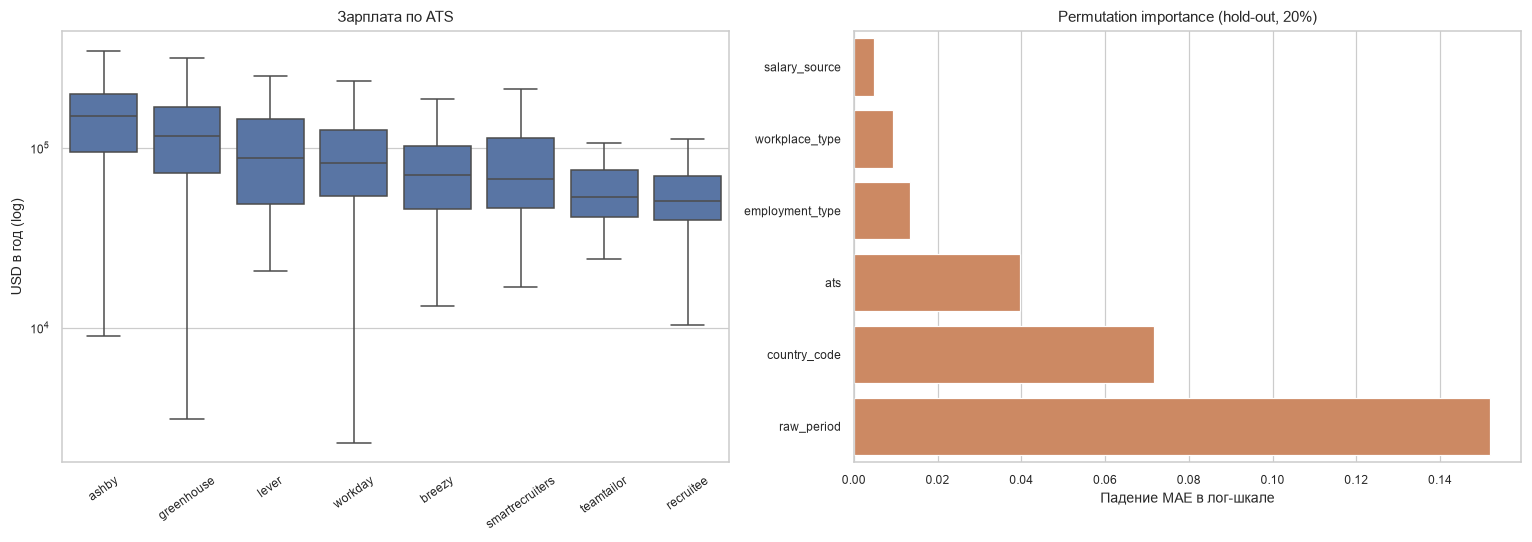

In [15]:
h12 = kruskal_table(df, "salary_mid", "ats", min_n=30)
display(h12["table"])
no_ats_cols = [c for c in BASE if c != "ats"]
no_ats_pred = cv_predict(df[no_ats_cols], df.log_salary)
ats_gain = mean_absolute_error(df.salary_mid, np.expm1(no_ats_pred)) - mean_absolute_error(df.salary_mid, np.expm1(BASE_PRED))

# Permutation importance на hold-out.
Xtr, Xte, ytr, yte = train_test_split(df[BASE], df.log_salary, test_size=0.2, random_state=RANDOM_STATE)
fitted = fit_hgb(Xtr, ytr)
Xte_encoded = np.hstack([
    fitted[1].transform(Xte[fitted[2]].astype(str)) if fitted[2] else np.empty((len(Xte), 0)),
    Xte[fitted[3]].to_numpy(dtype=float),
])
perm = permutation_importance(fitted[0], Xte_encoded, yte, n_repeats=10, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error", n_jobs=-1)
perm_series = pd.Series(perm.importances_mean, index=fitted[2] + fitted[3]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df[df.ats.isin(h12["table"].index)], x="ats", y="salary_mid", order=h12["table"].index, showfliers=False, ax=axes[0], color=BLUE)
axes[0].set_yscale("log"); axes[0].set_title("Зарплата по ATS"); axes[0].set_ylabel("USD в год (log)"); axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=35)
sns.barplot(x=perm_series.values, y=perm_series.index, ax=axes[1], color=ORANGE)
axes[1].set_title("Permutation importance (hold-out, 20%)")
axes[1].set_xlabel("Падение MAE в лог-шкале"); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

add_summary(
    12, "ats — сильный прокси типа компании", "Kruskal–Wallis, CV без ats, permutation importance",
    f"ε²={h12['eps2']:.2f}; Ashby ${h12['table'].loc['ashby','median']:,.0f}, Recruitee ${h12['table'].loc['recruitee','median']:,.0f}; прирост MAE ${ats_gain:,.0f}",
    "Подтверждена",
)

**Вывод.** ATS действительно сильно связан с зарплатой (ε² = 0.14): Ashby 151k, Greenhouse 117.5k, Workday 83k, Recruitee 51.2k. Удаление `ats` из модели ухудшает MAE на 1.1k, а permutation importance ставит его третьим после периода и страны. Это прокси типа компании (стартапы vs корпорации), а не причина зарплаты, но для прогноза признак полезен.

### Гипотеза 13. `company` / `company_id` улучшают прогноз при target encoding

,"MAE, $",прирост к base
модель,,
base,"39,934.000",0.000
+ company (target encoding),"37,226.000","2,708.000"
+ company_id (target encoding),"37,181.000","2,753.000"


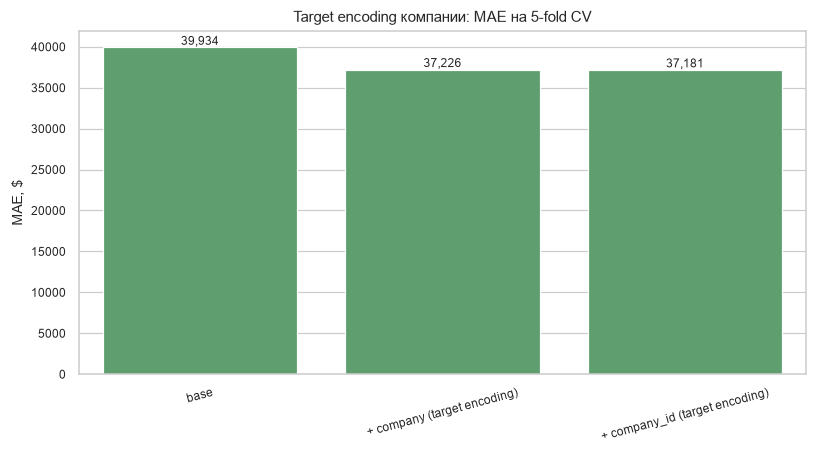

In [16]:
company_pred = cv_predict_target_encoding(df[BASE], df.log_salary, "company")
company_id_pred = cv_predict_target_encoding(df[BASE], df.log_salary, "company_id")
h13 = pd.DataFrame(
    {
        "модель": ["base", "+ company (target encoding)", "+ company_id (target encoding)"],
        "MAE, $": [
            mean_absolute_error(df.salary_mid, np.expm1(BASE_PRED)),
            mean_absolute_error(df.salary_mid, np.expm1(company_pred)),
            mean_absolute_error(df.salary_mid, np.expm1(company_id_pred)),
        ],
    }
)
h13["прирост к base"] = h13["MAE, $"].iloc[0] - h13["MAE, $"]
display(h13.round(0).set_index("модель"))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.barplot(data=h13, x="модель", y="MAE, $", ax=ax, color=GREEN)
ax.set_title("Target encoding компании: MAE на 5-fold CV")
ax.set_xlabel(""); ax.set_ylabel("MAE, $")
ax.tick_params(axis="x", rotation=15)
for i, v in enumerate(h13["MAE, $"]):
    ax.text(i, v + 300, f"{v:,.0f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

add_summary(
    13, "company/company_id улучшают прогноз", "out-of-fold target encoding внутри CV",
    f"MAE ${h13.loc[0,'MAE, $']:,.0f} → ${h13.loc[1,'MAE, $']:,.0f} (company) / ${h13.loc[2,'MAE, $']:,.0f} (company_id); прирост ${h13.loc[1,'прирост к base']:,.0f}",
    "Подтверждена",
)

**Вывод.** Target encoding компании даёт один из самых больших приростов: MAE падает с 39.9k до 37.2k (company) и 37.2k (company_id), то есть на ~7%. Но компаний 3 970, из них 1 274 встречаются один раз, поэтому кодировать нужно только внутри train-фолдов и со сглаживанием; иначе утечка и переобучение. `company_id` чуть точнее, потому что различает разные подразделения одной компании.

### Гипотеза 14. `salary_source` — признак качества данных, а не рынка

,median,size
salary_source,,
ats,"116,250.000",3095
description,"92,500.000",6060


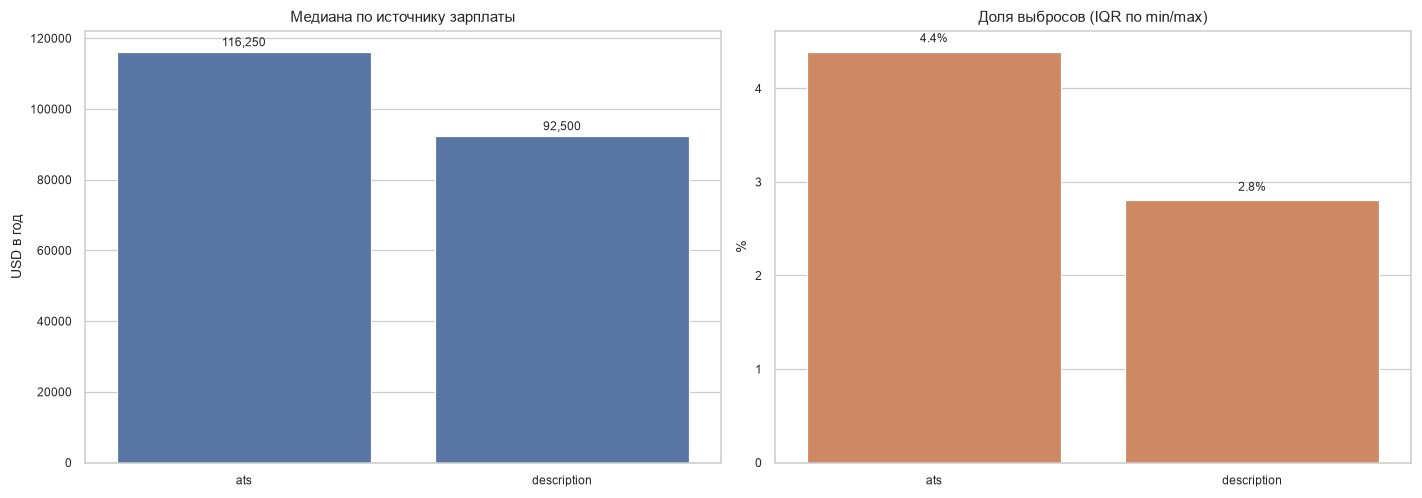

In [17]:
h14_med = df.groupby("salary_source")["salary_mid"].agg(["median", "size"])
display(h14_med.round(0))
ct_source_ats = pd.crosstab(df["salary_source"], df["ats"])
chi2_s, p_s, _, _ = stats.chi2_contingency(ct_source_ats)
outlier_by_source = df.groupby("salary_source")["outlier_any"].mean()
ols_source_raw = smf.ols("log_salary ~ C(salary_source)", data=df).fit(cov_type="HC1")
ols_source_adj = smf.ols("log_salary ~ C(salary_source) + C(ats) + C(raw_period)", data=df).fit(cov_type="HC1")
src_name = "C(salary_source)[T.description]"
src_raw_pct = (np.exp(ols_source_raw.params[src_name]) - 1) * 100
src_adj_pct = (np.exp(ols_source_adj.params[src_name]) - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
sns.barplot(data=h14_med.reset_index(), x="salary_source", y="median", ax=axes[0], color=BLUE)
axes[0].set_title("Медиана по источнику зарплаты"); axes[0].set_ylabel("USD в год"); axes[0].set_xlabel("")
for i, v in enumerate(h14_med["median"]):
    axes[0].text(i, v + 1500, f"{v:,.0f}", ha="center", fontsize=8)
sns.barplot(x=outlier_by_source.index, y=outlier_by_source.values * 100, ax=axes[1], color=ORANGE)
axes[1].set_title("Доля выбросов (IQR по min/max)"); axes[1].set_ylabel("%"); axes[1].set_xlabel("")
for i, v in enumerate(outlier_by_source.values * 100):
    axes[1].text(i, v + 0.1, f"{v:.1f}%", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

add_summary(
    14, "salary_source — качество данных, не рынок", "χ², OLS до/после контроля на ats и period, доля выбросов",
    f"медианы ${h14_med.loc['ats','median']:,.0f}/${h14_med.loc['description','median']:,.0f}; эффект {src_raw_pct:.1f}% → {src_adj_pct:.1f}% (p={pfmt(ols_source_adj.pvalues[src_name])}); выбросы {outlier_by_source['ats']:.1%}/{outlier_by_source['description']:.1%}",
    "Подтверждена",
)

**Вывод.** Без контроля `description` выглядит на 14% дешевле `ats`, но после учёта ATS и периода эффект исчезает (−1.3%, p = 0.40). Источник почти детерминирован платформой: у Workday 100% зарплат из description, у Greenhouse — 56%, у Ashby — 23% из ATS. Плюс в ats-выборке выше доля выбросов (4.4% против 2.8%). Это признак способа сбора данных, а не рынка; хранить его стоит для диагностики качества.

## 5. Занятость, период и ошибки нормализации

### Гипотеза 15. `employment_type` значим

,median,size
employment_type,,
full-time,"100,000.000",5857
contract,"81,000.000",124
other,"70,786.517",63
internship,"57,200.000",51
temporary,"57,200.000",99
part-time,"42,140.800",442


,группа A,n A,медиана A,группа B,n B,медиана B,p,p (Bonferroni)
0,full-time,5857,100000,part-time,442,42141,0.000,0.000
1,full-time,5857,100000,contract,124,81000,0.001,0.004
2,full-time,5857,100000,temporary,99,57200,0.000,0.000


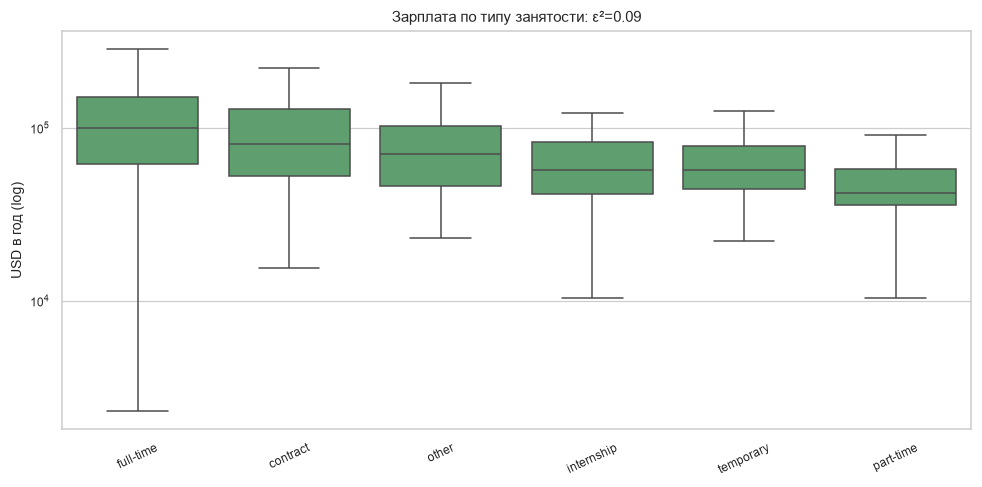

In [18]:
emp_df = df[df.employment_type.ne("Unknown")].copy()
h15 = kruskal_table(emp_df, "salary_mid", "employment_type", min_n=20)
display(h15["table"])
h15_pairs = pairwise_mw(
    emp_df, "salary_mid", "employment_type",
    [("full-time", "part-time"), ("full-time", "contract"), ("full-time", "temporary")],
)
display(h15_pairs.round(3))
no_emp_cols = [c for c in BASE if c != "employment_type"]
no_emp_pred = cv_predict(df[no_emp_cols], df.log_salary)
emp_gain = mean_absolute_error(df.salary_mid, np.expm1(no_emp_pred)) - mean_absolute_error(df.salary_mid, np.expm1(BASE_PRED))

fig, ax = plt.subplots(figsize=(9, 4.5))
order_emp = h15["table"].index
sns.boxplot(data=emp_df, x="employment_type", y="salary_mid", order=order_emp, showfliers=False, ax=ax, color=GREEN)
ax.set_yscale("log"); ax.set_ylabel("USD в год (log)"); ax.set_xlabel("")
ax.set_title(f"Зарплата по типу занятости: ε²={h15['eps2']:.2f}")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

add_summary(
    15, "employment_type значим", "Kruskal–Wallis, Mann–Whitney, CV без признака",
    f"ε²={h15['eps2']:.2f}; full-time ${h15['table'].loc['full-time','median']:,.0f}, part-time ${h15['table'].loc['part-time','median']:,.0f}; прирост MAE ${emp_gain:,.0f}",
    "Подтверждена (слабый прирост)",
)

**Вывод.** Различия значимы (ε² = 0.09): full-time 100k, contract 81k, temporary 57.2k, part-time 42.1k. Но после учёта периода и ATS вклад в модель небольшой (~0.3k MAE), потому что тип занятости сильно коррелирует с почасовой оплатой и платформой.

### Гипотеза 16. Исходный `salary_period` — информативный признак

,median,size
raw_period,,
year,"124,178.220",6634
day,"116,133.333",3
week,"109,200.000",14
hour,"50,034.400",2239
month,"47,912.360",265


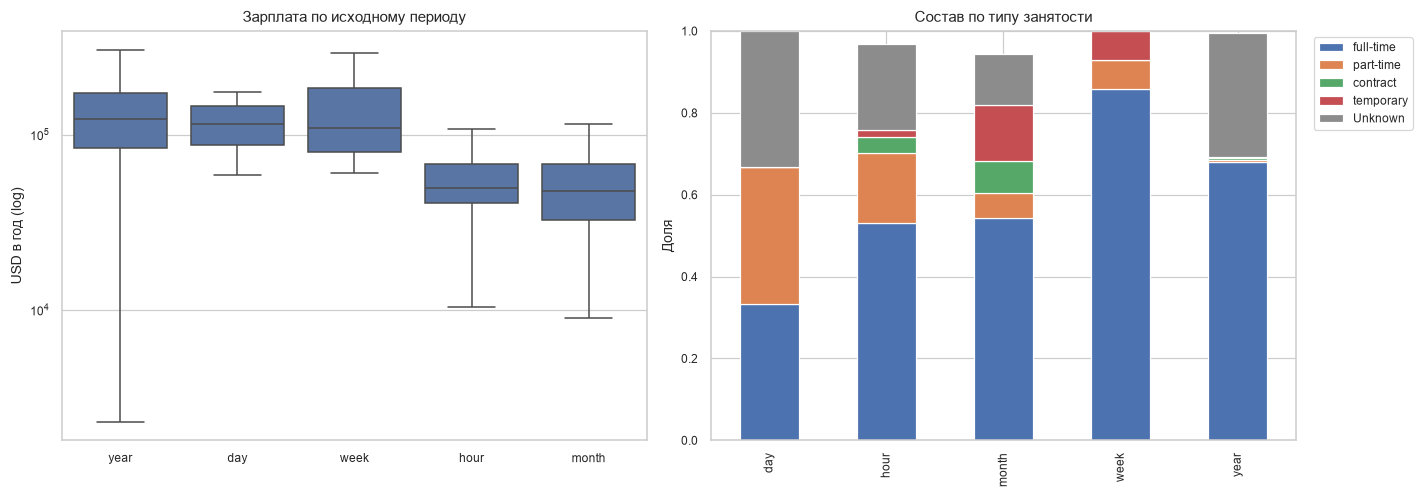

In [19]:
h16 = kruskal_table(df, "salary_mid", "raw_period", min_n=3)
display(h16["table"])
no_period_cols = [c for c in BASE if c != "raw_period"]
no_period_pred = cv_predict(df[no_period_cols], df.log_salary)
period_gain = mean_absolute_error(df.salary_mid, np.expm1(no_period_pred)) - mean_absolute_error(df.salary_mid, np.expm1(BASE_PRED))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
order_period = h16["table"].index
sns.boxplot(data=df, x="raw_period", y="salary_mid", order=order_period, showfliers=False, ax=axes[0], color=BLUE)
axes[0].set_yscale("log"); axes[0].set_title("Зарплата по исходному периоду"); axes[0].set_ylabel("USD в год (log)"); axes[0].set_xlabel("")
composition = pd.crosstab(df["raw_period"], df["employment_type"], normalize="index")
composition = composition[["full-time", "part-time", "contract", "temporary", "Unknown"]]
composition.plot(kind="bar", stacked=True, ax=axes[1], color=[BLUE, ORANGE, GREEN, RED, GREY])
axes[1].set_title("Состав по типу занятости"); axes[1].set_ylabel("Доля"); axes[1].set_xlabel("")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

add_summary(
    16, "Исходный salary_period информативен", "Kruskal–Wallis, CV без raw_period, состав по занятости",
    f"ε²={h16['eps2']:.2f}; year ${h16['table'].loc['year','median']:,.0f}, hour ${h16['table'].loc['hour','median']:,.0f}, month ${h16['table'].loc['month','median']:,.0f}; прирост MAE ${period_gain:,.0f}",
    "Подтверждена",
)

**Вывод.** Период — самый сильный категориальный признак по размеру эффекта (ε² = 0.33) и по вкладу в модель: без него MAE растёт с 39.9k до 46.6k. Но это не только рынок: `hour` — это в основном почасовые/частичные роли (53% full-time, 17% part-time, 21% без типа занятости), а `year` — офисные. Хранить исходный период как отдельную категорию нужно, но интерпретировать его стоит как «формат оплаты + тип роли».

### Гипотеза 17. Ошибки нормализации периода ухудшают модель

Подозрительных строк: 42 (0.5%); средняя середина $631,321 против $114,466


,title,raw_period,salary_text,salary_mid
51,Occupational Therapist,hour,120 – 140 USD per hour,"270,400.000"
384,Global Revenue Marketing Manager,month,"70,000 GBP- 80,000 GBP","1,200,000.000"
391,Global Revenue Marketing Manager,month,"65,000 EUR - 70,000 EUR","910,112.360"
641,Pallet Repair Technician,hour,$105\n- 400,"525,200.000"
906,Part-Time Laborist,hour,150 USD per hour,"312,000.000"
1089,Territory Representative,month,"$60,000-80,000","840,000.000"
1389,Entrepreneur in Residence (Remote),month,"$48,000 to $84,000","792,000.000"
1763,Education Administration and Supervision Teaching Faculty,month,"$60,000-$72,000","792,000.000"


,"MAE на чистых, $","MAE на подозрительных, $"
вариант,,
A: все строки,"37,815.000","499,757.000"
B: без подозрительных,"37,500.000","567,477.000"
C: все + флаг,"37,487.000","234,824.000"


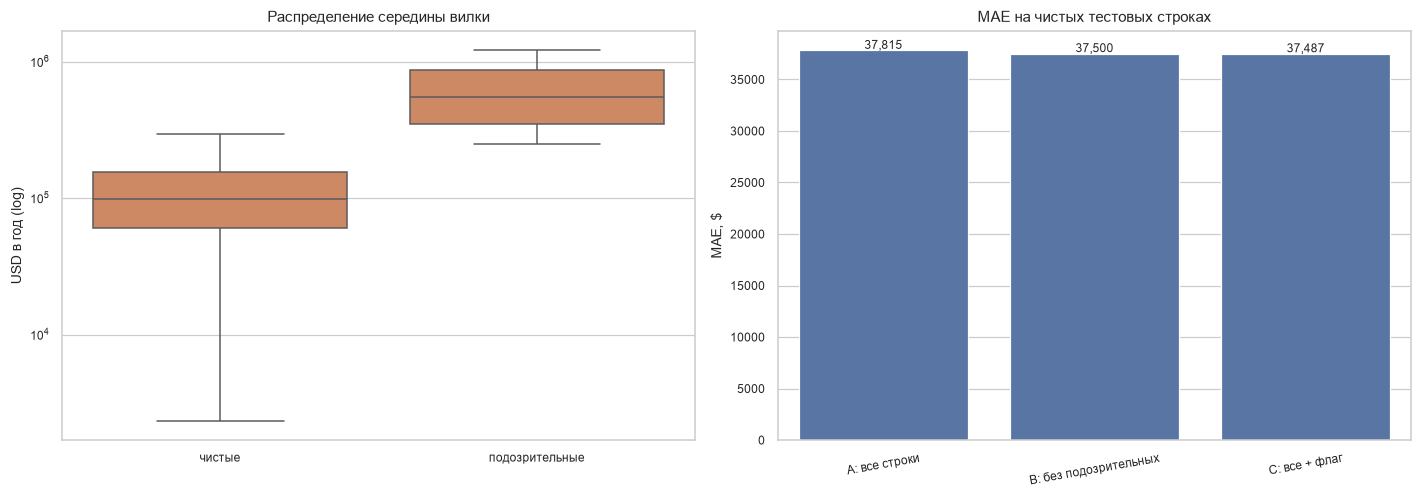

In [20]:
suspect = df[df.period_suspect]
clean = df[~df.period_suspect]
print(f"Подозрительных строк: {len(suspect)} ({len(suspect)/len(df):.1%}); средняя середина ${suspect.salary_mid.mean():,.0f} против ${clean.salary_mid.mean():,.0f}")
display(suspect[["title", "raw_period", "salary_text", "salary_mid"]].head(8))

pred_all = np.full(len(df), np.nan)
pred_clean_train = np.full(len(df), np.nan)
pred_flag = np.full(len(df), np.nan)
for train_idx, test_idx in FOLDS:
    pred_all[test_idx] = predict_hgb(fit_hgb(df[BASE].iloc[train_idx], df.log_salary.iloc[train_idx]), df[BASE].iloc[test_idx])
    clean_train_idx = train_idx[~df.period_suspect.iloc[train_idx].to_numpy()]
    pred_clean_train[test_idx] = predict_hgb(
        fit_hgb(df[BASE].iloc[clean_train_idx], df.log_salary.iloc[clean_train_idx]), df[BASE].iloc[test_idx]
    )
    X_flag_train = df[BASE].iloc[train_idx].copy()
    X_flag_test = df[BASE].iloc[test_idx].copy()
    X_flag_train["period_suspect"] = df.period_suspect.iloc[train_idx].to_numpy()
    X_flag_test["period_suspect"] = df.period_suspect.iloc[test_idx].to_numpy()
    pred_flag[test_idx] = predict_hgb(fit_hgb(X_flag_train, df.log_salary.iloc[train_idx]), X_flag_test)

h17 = pd.DataFrame(
    {
        "вариант": ["A: все строки", "B: без подозрительных", "C: все + флаг"],
        "MAE на чистых, $": [
            mean_absolute_error(clean.salary_mid, np.expm1(pred_all[~df.period_suspect])),
            mean_absolute_error(clean.salary_mid, np.expm1(pred_clean_train[~df.period_suspect])),
            mean_absolute_error(clean.salary_mid, np.expm1(pred_flag[~df.period_suspect])),
        ],
        "MAE на подозрительных, $": [
            mean_absolute_error(suspect.salary_mid, np.expm1(pred_all[df.period_suspect])),
            mean_absolute_error(suspect.salary_mid, np.expm1(pred_clean_train[df.period_suspect])),
            mean_absolute_error(suspect.salary_mid, np.expm1(pred_flag[df.period_suspect])),
        ],
    }
)
display(h17.round(0).set_index("вариант"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
plot_bad = df.assign(group=np.where(df.period_suspect, "подозрительные", "чистые"))
sns.boxplot(data=plot_bad, x="group", y="salary_mid", showfliers=False, ax=axes[0], color=ORANGE)
axes[0].set_yscale("log"); axes[0].set_title("Распределение середины вилки"); axes[0].set_ylabel("USD в год (log)"); axes[0].set_xlabel("")
sns.barplot(data=h17, x="вариант", y="MAE на чистых, $", ax=axes[1], color=BLUE)
axes[1].set_title("MAE на чистых тестовых строках"); axes[1].set_ylabel("MAE, $"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=10)
for i, v in enumerate(h17["MAE на чистых, $"]):
    axes[1].text(i, v + 150, f"{v:,.0f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

add_summary(
    17, "Ошибки периода ухудшают модель", "CV: обучение со строками / без / с флагом, оценка на чистых",
    f"{len(suspect)} строк ({len(suspect)/len(df):.1%}); MAE на чистых ${h17.loc[0,'MAE на чистых, $']:,.0f} → ${h17.loc[1,'MAE на чистых, $']:,.0f}; ошибка на подозрительных ~${h17.loc[0,'MAE на подозрительных, $']:,.0f}",
    "Частично подтверждена",
)

**Вывод.** Подозрительных строк мало (42, 0.5%), но они очень дорогие: средняя середина 631k против 114k, ошибка модели на них ~500k. Исключение таких строк из обучения снижает MAE на чистых тестовых строках всего на ~0.3k (0.8%), потому что их доля мала; флаг в модели даёт примерно тот же эффект. Вывод: ошибки надо находить и исключать/флагать, но глобального улучшения метрики от этого ждать не стоит — эффект локальный.

## 6. Текст и пропуски

### Гипотеза 18. `description` содержит сигнал о зарплате

In [ ]:
descriptions = df["description"].fillna("")
clean_descriptions = descriptions.str.replace(r"[\$\u20ac\u00a3]\s?\d[\d,\.]*\s?[kK]?", " [money] ", regex=True)
clean_descriptions = clean_descriptions.str.replace(
    r"\b\d[\d,\.]*\s?[kK]?\s?(usd|eur|gbp|pln|cad)?\s?(per|/|a|an)\s?(hour|hr|year|yr|month|week|day|annum)",
    " [pay] ", regex=True,
)
clean_descriptions = clean_descriptions.str.replace(
    r"\b(salary|compensation|pay range|hourly rate|annual salary)\b", " [pay] ", regex=True, case=False
)
money_share = descriptions.str.contains(r"[\$\u20ac\u00a3]\s?\d", regex=True).mean()
money_share_clean = clean_descriptions.str.contains(r"[\$\u20ac\u00a3]\s?\d", regex=True).mean()
print(f"Денежные упоминания: raw {money_share:.1%}, после очистки {money_share_clean:.1%}")

def text_cv(text, label):
    pipe = Pipeline(
        [
            ("tfidf", TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3, sublinear_tf=True, stop_words="english")),
            ("ridge", Ridge(alpha=1.0)),
        ]
    )
    pred = np.full(len(df), np.nan)
    for train_idx, test_idx in FOLDS:
        pipe.fit(text.iloc[train_idx], df.log_salary.iloc[train_idx])
        pred[test_idx] = pipe.predict(text.iloc[test_idx])
    return pred, metrics(pred, df.salary_mid)

pred_text_raw, m_text_raw = text_cv(descriptions, "raw")
pred_text_clean, m_text_clean = text_cv(clean_descriptions, "clean")

metadata_pipe = Pipeline(
    [
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=5)),
        ("ridge", Ridge(alpha=1.0)),
    ]
)
pred_meta = np.full(len(df), np.nan)
for train_idx, test_idx in FOLDS:
    metadata_pipe.fit(df[BASE].iloc[train_idx], df.log_salary.iloc[train_idx])
    pred_meta[test_idx] = metadata_pipe.predict(df[BASE].iloc[test_idx])

combined = ColumnTransformer(
    [
        ("text", TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3, sublinear_tf=True, stop_words="english"), "description"),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), BASE),
    ],
    sparse_threshold=1.0,
)
combined_pipe = Pipeline([("features", combined), ("ridge", Ridge(alpha=1.0))])
pred_combined = np.full(len(df), np.nan)
for train_idx, test_idx in FOLDS:
    combined_pipe.fit(df.iloc[train_idx], df.log_salary.iloc[train_idx])
    pred_combined[test_idx] = combined_pipe.predict(df.iloc[test_idx])

m_meta = metrics(pred_meta, df.salary_mid)
m_combined = metrics(pred_combined, df.salary_mid)
h18 = pd.DataFrame(
    {
        "модель": ["metadata (one-hot)", "description raw", "description clean", "metadata + description"],
        "MAE, $": [m_meta["MAE, $"], m_text_raw["MAE, $"], m_text_clean["MAE, $"], m_combined["MAE, $"]],
        "RMSLE": [m_meta["RMSLE"], m_text_raw["RMSLE"], m_text_clean["RMSLE"], m_combined["RMSLE"]],
        "R2 (log)": [m_meta["R2 (log)"], m_text_raw["R2 (log)"], m_text_clean["R2 (log)"], m_combined["R2 (log)"]],
    }
).set_index("модель")
display(h18)

df["desc_words"] = descriptions.str.split().str.len()
length_corr = stats.spearmanr(df["desc_words"], df["salary_mid"]).statistic
len_pred = cv_predict(df[BASE], df.log_salary, extra={"desc_words": df["desc_words"]})
len_gain = mean_absolute_error(df.salary_mid, np.expm1(BASE_PRED)) - mean_absolute_error(df.salary_mid, np.expm1(len_pred))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
sns.barplot(data=h18.reset_index(), x="модель", y="MAE, $", ax=ax, palette=[GREY, ORANGE, GREEN, BLUE])
ax.set_title("Текст описания против метаданных: MAE на 5-fold CV")
ax.set_ylabel("MAE, $"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=10)
for i, v in enumerate(h18["MAE, $"]):
    ax.text(i, v + 500, f"{v:,.0f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

add_summary(
    18, "description содержит сигнал", "TF-IDF + Ridge, CV; очистка денежных упоминаний; длина описания",
    f"MAE metadata ${h18.loc['metadata (one-hot)','MAE, $']:,.0f} → text raw ${h18.loc['description raw','MAE, $']:,.0f} / clean ${h18.loc['description clean','MAE, $']:,.0f}; деньги в {money_share:.0%} описаний; ρ(длина, зарплата)={length_corr:.2f}",
    "Подтверждена (с оговоркой об утечке)",
)

Денежные упоминания: raw 86.8%, после очистки 0.0%


**Вывод.** Описание — самый сильный источник сигнала: одна TF-IDF + Ridge обгоняет метаданные (MAE 27.1k против 40.6k), а совместная модель даёт 25.7k. Но 87% описаний содержат явные суммы, поэтому «сырой» текст частично подглядывает в ответ. После удаления денежных паттернов качество почти не падает (MAE 27.7k), значит сигнал о роли/стеке/уровне остаётся. Длина описания сама по себе слабая (ρ = 0.27) и модели не помогает.

### Гипотеза 19. Факт пропуска — сам по себе признак

,пропусков,доля,медиана есть,медиана нет,отношение,p
поле,,,,,,
seniority,8543,0.933,"63,567.191","102,500.000",1.612,0.000
workplace_type,5147,0.562,"113,500.000","88,850.000",0.783,0.000
country_code,1122,0.123,"95,500.000","129,300.000",1.354,0.000
language,5661,0.618,"109,048.000","93,646.915",0.859,0.000
department,3755,0.410,"115,000.000","82,000.000",0.713,0.000
employment_type,2516,0.275,"92,500.000","120,000.000",1.297,0.000
region,6965,0.761,"100,000.000","99,320.000",0.993,0.515
city,6787,0.741,"95,000.000","100,000.000",1.053,0.081


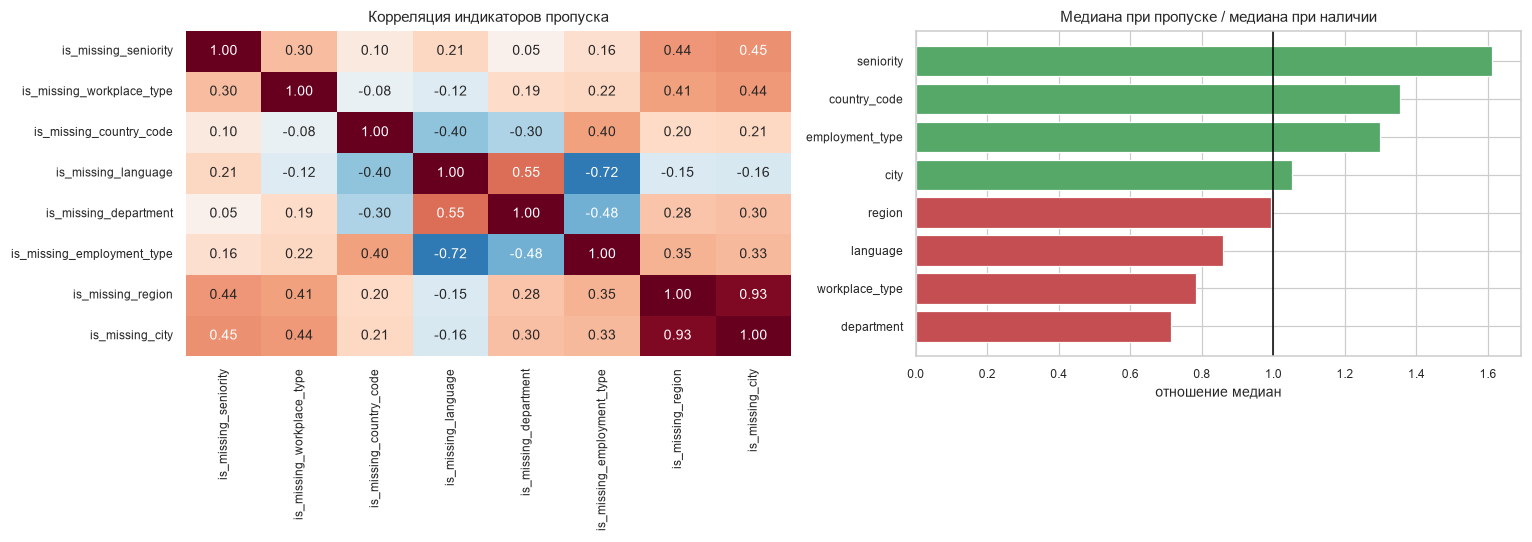

In [ ]:
missing_rows = []
for col in MISSING_FIELDS:
    flag = df[f"is_missing_{col}"].eq(1)
    present = df.loc[~flag, "salary_mid"]
    absent = df.loc[flag, "salary_mid"]
    p = stats.mannwhitneyu(present, absent).pvalue
    missing_rows.append(
        {
            "поле": col,
            "пропусков": int(flag.sum()),
            "доля": flag.mean(),
            "медиана есть": present.median(),
            "медиана нет": absent.median(),
            "отношение": absent.median() / present.median(),
            "p": p,
        }
    )
h19_table = pd.DataFrame(missing_rows).set_index("поле")
display(h19_table.round(3))

missing_flags = [f"is_missing_{c}" for c in MISSING_FIELDS]
missing_pred = cv_predict(df[BASE], df.log_salary, extra={c: df[c] for c in missing_flags})
missing_gain = mean_absolute_error(df.salary_mid, np.expm1(BASE_PRED)) - mean_absolute_error(df.salary_mid, np.expm1(missing_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df[missing_flags].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0], cbar=False)
axes[0].set_title("Корреляция индикаторов пропуска")
plot_ratio = h19_table["отношение"].sort_values().reset_index()
colors = [RED if x < 1 else GREEN for x in plot_ratio["отношение"]]
axes[1].barh(plot_ratio["поле"], plot_ratio["отношение"], color=colors)
axes[1].axvline(1, color="black", linewidth=1)
axes[1].set_title("Медиана при пропуске / медиана при наличии")
axes[1].set_xlabel("отношение медиан")
plt.tight_layout()
plt.show()

add_summary(
    19, "Факт пропуска — признак", "Mann–Whitney по каждой колонке; CV с индикаторами пропусков",
    f"отношения медиан {h19_table['отношение'].min():.2f}–{h19_table['отношение'].max():.2f}; прирост MAE ${missing_gain:,.0f}",
    "Частично подтверждена",
)

**Вывод.** Описательно пропуски очень информативны: без `seniority` медиана в 1.61 раза выше, без `department` — в 0.71 раза, без `country_code` — в 1.35 раза (все p < 1e−28). Но как дополнительные признаки к модели они не работают: прирост MAE отрицательный (−42), потому что пропуски уже представлены категорией «Unknown» в базовых признаках. Пропуски структурны (связаны с ATS и форматом), но отдельные `is_missing_*` избыточны.

## 7. Служебные признаки и даты

### Гипотеза 20. `salary_min` — самый сильный предиктор `salary_max`

,"MAE, $",RMSLE,R2 (log)
модель,,,
без salary_min,"47,163.392",0.468,0.466
с salary_min,"17,368.066",0.180,0.921


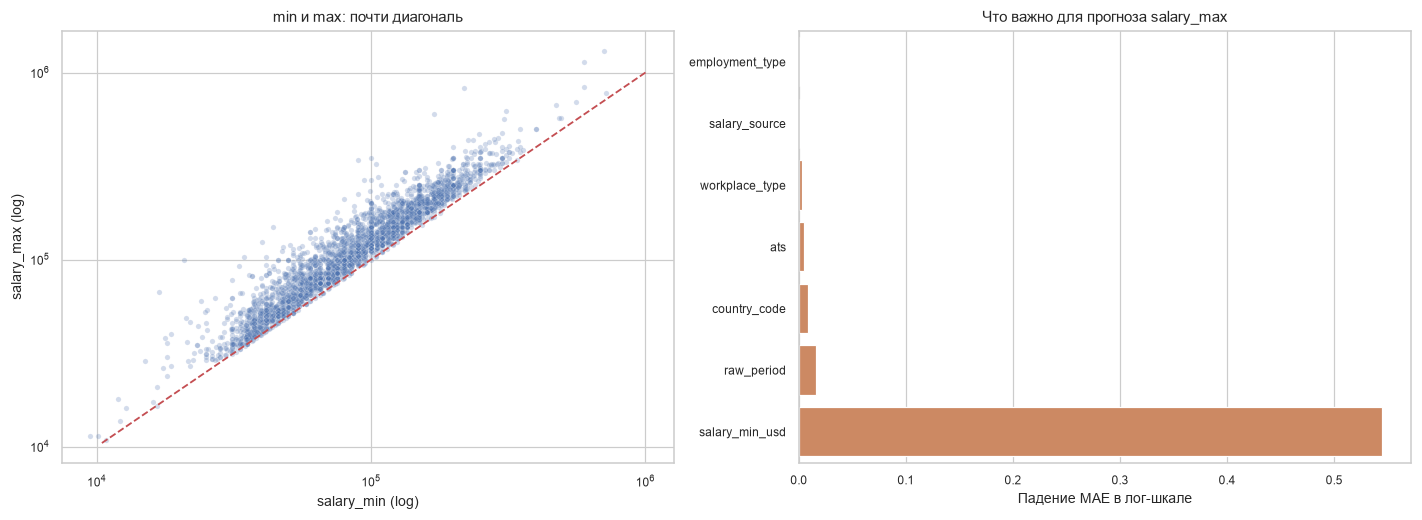

In [ ]:
max_without = cv_predict(df[BASE], np.log1p(df.salary_max_usd))
max_with = cv_predict(df[BASE + ["salary_min_usd"]], np.log1p(df.salary_max_usd))
h20 = pd.DataFrame(
    {
        "модель": ["без salary_min", "с salary_min"],
        "MAE, $": [
            mean_absolute_error(df.salary_max_usd, np.expm1(max_without)),
            mean_absolute_error(df.salary_max_usd, np.expm1(max_with)),
        ],
        "RMSLE": [
            metrics(max_without, df.salary_max_usd)["RMSLE"],
            metrics(max_with, df.salary_max_usd)["RMSLE"],
        ],
        "R2 (log)": [
            metrics(max_without, df.salary_max_usd)["R2 (log)"],
            metrics(max_with, df.salary_max_usd)["R2 (log)"],
        ],
    }
).set_index("модель")
display(h20)

Xtr20, Xte20, ytr20, yte20 = train_test_split(df[BASE + ["salary_min_usd"]], np.log1p(df.salary_max_usd), test_size=0.2, random_state=RANDOM_STATE)
fit20 = fit_hgb(Xtr20, ytr20)
Xte20_encoded = np.hstack([
    fit20[1].transform(Xte20[fit20[2]].astype(str)) if fit20[2] else np.empty((len(Xte20), 0)),
    Xte20[fit20[3]].to_numpy(dtype=float),
])
perm20 = permutation_importance(fit20[0], Xte20_encoded, yte20, n_repeats=10, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error", n_jobs=-1)
perm20_series = pd.Series(perm20.importances_mean, index=fit20[2] + fit20[3]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x="salary_min_usd", y="salary_max_usd", alpha=0.25, s=12, ax=axes[0], color=BLUE)
axes[0].plot(lim, lim, color=RED, linestyle="--")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_title("min и max: почти диагональ")
axes[0].set_xlabel("salary_min (log)"); axes[0].set_ylabel("salary_max (log)")
sns.barplot(x=perm20_series.values, y=perm20_series.index, ax=axes[1], color=ORANGE)
axes[1].set_title("Что важно для прогноза salary_max")
axes[1].set_xlabel("Падение MAE в лог-шкале"); axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

add_summary(
    20, "salary_min — главный предиктор salary_max", "CV с/без salary_min; permutation importance",
    f"MAE ${h20.loc['без salary_min','MAE, $']:,.0f} → ${h20.loc['с salary_min','MAE, $']:,.0f}; R2 {h20.loc['без salary_min','R2 (log)']:.2f} → {h20.loc['с salary_min','R2 (log)']:.2f}",
    "Подтверждена",
)

**Вывод.** Если таргет — `max`, то `min` доминирует: MAE падает с 47.2k до 17.4k, R² растёт с 0.47 до 0.92, permutation importance в 10+ раз выше остальных признаков. Но это не помогает холодному прогнозу: `min` — уже известная часть той же вилки. Практический смысл — восстановление границ/интервалов, а не замена основного таргета.

### Гипотеза 21. Даты дают слабый, но проверяемый сигнал

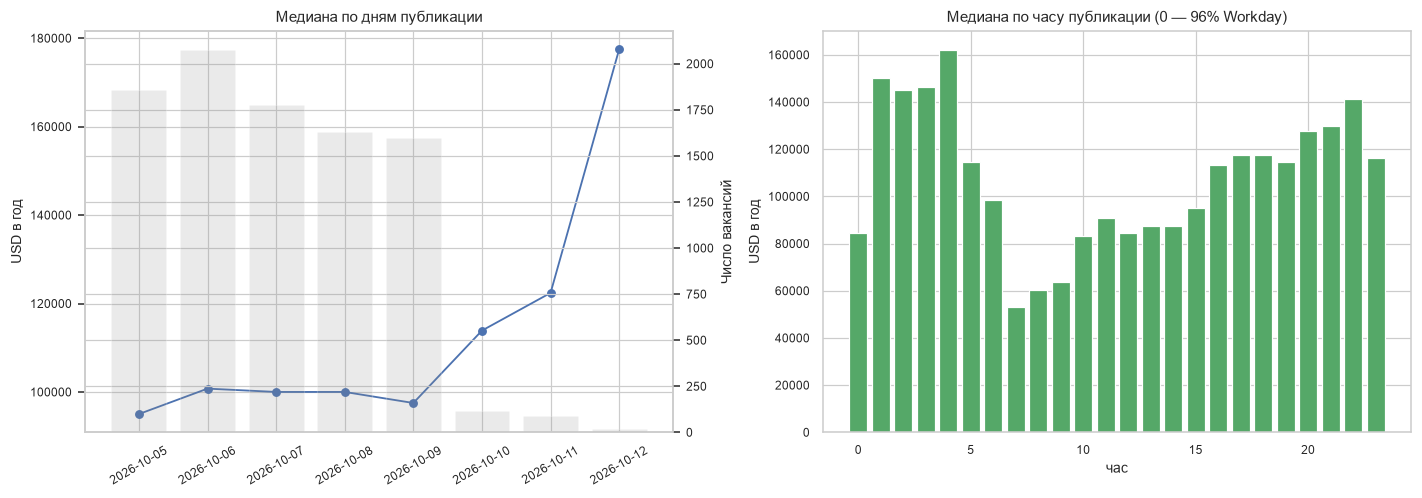

In [ ]:
date_min, date_max = df["posted"].min(), df["posted"].max()
lag_corr = stats.spearmanr(df["lag_hours"], df["salary_mid"])
days_corr = stats.spearmanr(df["days_since_start"], df["salary_mid"])
dow_kw = stats.kruskal(*[g["salary_mid"].to_numpy() for _, g in df.groupby("posted_dow") if len(g) >= 20])
hour_kw = stats.kruskal(*[g["salary_mid"].to_numpy() for _, g in df.groupby("posted_hour") if len(g) >= 20])

date_pred = cv_predict(
    df[BASE], df.log_salary,
    extra={
        "posted_dow": df["posted_dow"],
        "posted_hour": df["posted_hour"],
        "lag_hours": df["lag_hours"],
        "days_since_start": df["days_since_start"],
    },
)
date_gain = mean_absolute_error(df.salary_mid, np.expm1(BASE_PRED)) - mean_absolute_error(df.salary_mid, np.expm1(date_pred))

daily = df.groupby(df["posted"].dt.date)["salary_mid"].agg(["median", "size"])
hourly = df.groupby("posted_hour")["salary_mid"].agg(["median", "size"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(pd.to_datetime(daily.index), daily["median"], marker="o", color=BLUE)
axes[0].set_title("Медиана по дням публикации")
axes[0].set_ylabel("USD в год"); axes[0].tick_params(axis="x", rotation=30)
ax2 = axes[0].twinx()
ax2.bar(pd.to_datetime(daily.index), daily["size"], alpha=0.18, color=GREY)
ax2.set_ylabel("Число вакансий")
axes[1].bar(hourly.index, hourly["median"], color=GREEN)
axes[1].set_title("Медиана по часу публикации (0 — 96% Workday)")
axes[1].set_xlabel("час"); axes[1].set_ylabel("USD в год")
plt.tight_layout()
plt.show()

add_summary(
    21, "Даты дают слабый сигнал", "Spearman, Kruskal–Wallis по дню/часу, CV с датами",
    f"окно {date_min.date()}–{date_max.date()} (одна неделя); ρ(lag, зарплата)={lag_corr.statistic:.3f}, ρ(день, зарплата)={days_corr.statistic:.3f}; p(день недели)={pfmt(dow_kw.pvalue)}, p(час)={pfmt(hour_kw.pvalue)}; прирост MAE ${date_gain:,.0f}",
    "Не подтверждена",
)

**Вывод.** Сезонность проверить нельзя: все вакансии опубликованы в одну неделю (5–12 октября 2026). День недели формально значим (p = 0.008), но эффект держится на 200 выходных вакансиях; час публикации значим (p < 1e−100), но это артефакт источника: 96% вакансий в 00:00 — Workday с более низкими зарплатами. Lag и давность дают слабые корреляции, а добавление дат в модель ухудшает MAE на 0.3k. Для прогноза даты бесполезны; для анализа сезонности нужен более длинный период.

## 8. Сводная таблица гипотез

In [ ]:
summary_df = pd.DataFrame(SUMMARY)
display(summary_df[["№", "Гипотеза", "Вывод"]])
display(summary_df[["№", "Ключевой результат"]].set_index("№"))

verdict_counts = summary_df["Вывод"].value_counts()
print("Распределение выводов:")
for verdict, count in verdict_counts.items():
    print(f"  {verdict}: {count}")

,№,Гипотеза,Вывод
0,1,Логарифм зарплаты как таргет,Подтверждена (с оговоркой)
1,2,Один таргет — середина вилки,Подтверждена
2,3,Ширина вилки — отдельный сигнал,Частично подтверждена
3,4,Уровень позиции влияет на зарплату,Подтверждена
4,5,Уровень восстанавливается из title,Частично подтверждена
5,6,Семейство профессии значимо,Подтверждена
6,7,"department полезен там, где заполнен",Подтверждена (на подвыборке)
7,8,Страна значимо влияет на зарплату,Подтверждена
8,9,remote > hybrid > onsite,Частично подтверждена
9,10,Внутри США штат/город значимы,Подтверждена


,Ключевой результат
№,
1,"skew 3.56 → -0.08; RMSLE 0.738 → 0.451; MAE $41,789 → $39,934"
2,"r=0.944, ρ=0.958; RMSLE mid 0.451 против 0.448/0.468"
3,"ρ(spread, mid)=0.75, ρ(spread_pct, mid)=0.24; R2 spread_pct=0.083; Kruskal по period p=1.1e-71"
4,"ε²=0.20; медианы entry→executive $50,062→$135,000; senior vs executive p=0.124"
5,"accuracy 0.61 против majority 0.44; base+family $37,739 → +seniority_pred $34,606"
6,"ε²=0.17; медианы $56,778–$161,500; прирост MAE $2,195"
7,"n=5,400; ε²=0.11; Engineering $185,125 против Retail $39,000; прирост MAE $1,080"
8,"ε²=0.09; US $107,500, FR $40,338, IT $44,494"
9,"медианы $130,000/$117,575/$76,960; remote +45% → +5.9% (p=0.015)"


Распределение выводов:
  Подтверждена: 10
  Частично подтверждена: 6
  Подтверждена (с оговоркой): 1
  Подтверждена (на подвыборке): 1
  Подтверждена (слабый прирост): 1
  Подтверждена (с оговоркой об утечке): 1
  Не подтверждена: 1


## 9. Что вышло в итоге

Из 21 гипотезы **14 подтвердились** полностью или с оговоркой, **6 — частично**, **1 не подтвердилась**. Но практическая ценность гипотез разная: часть из них — про статистическую значимость, часть — про реальный прирост модели.

### Главное

1. **Таргет.** Оптимальная постановка — `log1p(salary_mid)`: распределение становится почти симметричным, RMSLE падает с 0.738 до 0.451. Середина вилки — хороший единый таргет: min и max коррелируют на 0.94–0.96, а отдельные модели для границ почти не отличаются по ошибке.
2. **Сильные признаки.** По приросту MAE в базовой модели лидируют исходный `salary_period` (+6.6k), target encoding компании (+2.7k), `job_family` (+2.2k), `ats` (+1.1k), `department` (+1.1k), штат США (+0.9k). Предсказанный из title уровень добавляет ещё ~3.1k поверх семейства профессий.
3. **Слабые, но полезные.** `employment_type`, `workplace_type` и `salary_source` значимы статистически, но после контроля на период/ATS дают мало. Remote-премия после контроля падает с +45% до +6%, hybrid — почти исчезает.
4. **Текст.** `description` — самый сильный источник, но 87% описаний содержат явные суммы. Даже после удаления денежных паттернов TF-IDF + Ridge даёт MAE 27.7k против 40.6k у метаданных, поэтому текст надо использовать, но с маскировкой зарплатных упоминаний, чтобы не получить утечку.
5. **Пропуски.** Сами по себе информативны (без `seniority` медиана выше в 1.6 раза, без `department` — ниже в 0.7 раза), но дополнительные `is_missing_*` не улучшают модель: пропуск уже закодирован категорией «Unknown».
6. **Даты.** Сезонность проверить невозможно: окно — одна неделя. Час публикации — артефакт источника (00:00 = Workday), добавление дат ухудшает MAE. Для временного анализа нужен более длинный период.

### Что не сработало

- Ширина вилки как отдельный таргет: относительная ширина слабо предсказуется (R² = 0.08), абсолютная почти полностью объясняется уровнем зарплаты.
- Точное восстановление уровня из title: accuracy 0.61 — лучше majority 0.44, но mid/senior/internship путаются; как признак полезно, как замена `seniority` — нет.
- `salary_source` как рыночный сигнал: эффект исчезает после контроля на ATS и период.
- Даты и пропуски как дополнительные признаки модели.

### Рекомендуемый набор признаков

Для «холодного» прогноза (без `salary_min`/`salary_max`):

- `raw_period`, `ats`, `country_code`, `state_model`, `employment_type`, `workplace_type`;
- `job_family`, `seniority_pred`, `dept_group`;
- target encoding `company`/`company_id` только внутри train-фолдов;
- очищенный от денежных упоминаний текст описания (TF-IDF/эмбеддинги);
- флаг `period_suspect` — для диагностики, а не как обычный признак.

Не включать в холодный прогноз `salary_min` и `salary_max`: они дают «идеальные» метрики, но это утечка. Их место — восстановление интервалов, когда одна из границ уже известна.

### Ограничения

Данные наблюдательные и содержат только вакансии с указанной зарплатой; курсы валют зафиксированы на одну дату; пересчёт периода использует стандартные 2080 часов/260 дней; окно наблюдения — одна неделя; проверки множественные, p-value стоит воспринимать как ориентир; семейства профессий и штаты извлечены эвристиками. Всё это ограничивает причинные интерпретации — но не мешает использовать признаки для прогноза.

### Следующие шаги

1. Собрать более длинную историю и проверить сезонность/тренды на временном hold-out.
2. Заменить эвристики `job_family` и `seniority` на обучаемые модели по title/description.
3. Добавить эмбеддинги описания и попробовать градиентный бустинг поверх них.
4. Перейти от точечного прогноза к квантильной регрессии — для вилки и интервалов.
5. Отдельно моделировать почасовые/part-time вакансии: у них другой механизм формирования зарплаты.